#### Load Processed Dataset

Load the cleaned transaction dataset containing promotional and discount features for exploratory analysis.

In [1]:
import pandas as pd

transactions_promo = pd.read_csv("../data/processed/transactions_promo.csv")

print("Dataset shape:", transactions_promo.shape)
transactions_promo.head()

/tmp/ipykernel_2614511/2390039353.py:3: DtypeWarning: Columns (12,13) have mixed types. Specify dtype option on import or set low_memory=False.
  transactions_promo = pd.read_csv("../data/processed/transactions_promo.csv")


Dataset shape: (2595732, 21)


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,...,COUPON_MATCH_DISC,display_values,mailer_values,promotion_records,retail_discount_amount,coupon_discount_amount,coupon_match_discount_amount,total_discount,estimated_original_value,discount_percentage
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,...,0.0,NaN,NaN,NaN,0.60,-0.0,-0.0,0.60,1.99,30.150754
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,...,0.0,NaN,NaN,NaN,-0.00,-0.0,-0.0,0.00,0.82,0.000000
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,...,0.0,NaN,NaN,NaN,0.30,-0.0,-0.0,0.30,1.29,23.255814
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,...,0.0,NaN,NaN,NaN,-0.00,-0.0,-0.0,0.00,1.21,0.000000
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,...,0.0,NaN,NaN,NaN,0.39,-0.0,-0.0,0.39,1.89,20.634921


#### Identify Numerical Variables

Identify the numerical variables that will be used for descriptive statistical analysis.

In [2]:
numerical_cols = transactions_promo.select_dtypes(include="number").columns

print("Number of numerical columns:", len(numerical_cols))
print(numerical_cols.tolist())

Number of numerical columns: 19
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC', 'promotion_records', 'retail_discount_amount', 'coupon_discount_amount', 'coupon_match_discount_amount', 'total_discount', 'estimated_original_value', 'discount_percentage']


#### Descriptive Statistics

Calculate descriptive statistics to understand the central values and spread of purchasing and discount-related variables.

In [3]:
analysis_cols = [
    "SALES_VALUE",
    "QUANTITY",
    "total_discount",
    "discount_percentage",
    "estimated_original_value"
]

transactions_promo[analysis_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SALES_VALUE,2595732.0,3.104120,4.182274,0.0,1.29,2.000000,3.490000,840.0
QUANTITY,2595732.0,100.428558,1153.436211,0.0,1.00,1.000000,1.000000,89638.0
total_discount,2595732.0,0.558043,1.280160,0.0,0.00,0.070000,0.700000,180.0
discount_percentage,2585560.0,13.857140,17.642430,0.0,0.00,4.068038,25.062657,100.0
estimated_original_value,2595732.0,3.662163,4.670147,0.0,1.59,2.590000,3.990000,840.0


#### Measures of Central Tendency

Calculate the mean, median and mode to understand the typical values of purchasing and discount-related variables.

In [4]:
central_tendency = pd.DataFrame({
    "Mean": transactions_promo[analysis_cols].mean(),
    "Median": transactions_promo[analysis_cols].median(),
    "Mode": transactions_promo[analysis_cols].mode().iloc[0]
})

central_tendency

,Mean,Median,Mode
SALES_VALUE,3.104120,2.000000,1.00
QUANTITY,100.428558,1.000000,1.00
total_discount,0.558043,0.070000,0.00
discount_percentage,13.857140,4.068038,0.00
estimated_original_value,3.662163,2.590000,2.99


#### Measures of Dispersion

Calculate variance, range and interquartile range to understand the variability in purchasing and discount-related variables.

In [5]:
dispersion = pd.DataFrame({
    "Variance": transactions_promo[analysis_cols].var(),
    "Range": (
        transactions_promo[analysis_cols].max()
        - transactions_promo[analysis_cols].min()
    ),
    "IQR": (
        transactions_promo[analysis_cols].quantile(0.75)
        - transactions_promo[analysis_cols].quantile(0.25)
    ),
    "Standard Deviation": transactions_promo[analysis_cols].std()
})

dispersion

,Variance,Range,IQR,Standard Deviation
SALES_VALUE,1.749142e+01,840.0,2.200000,4.182274
QUANTITY,1.330415e+06,89638.0,0.000000,1153.436211
total_discount,1.638809e+00,180.0,0.700000,1.280160
discount_percentage,3.112553e+02,100.0,25.062657,17.642430
estimated_original_value,2.181027e+01,840.0,2.400000,4.670147


#### Distribution Shape and Skewness

Calculate skewness to identify whether purchasing and discount-related variables have symmetric or asymmetric distributions.

In [6]:
skewness = transactions_promo[analysis_cols].skew()

print("Skewness of numerical variables:")
print(skewness.sort_values(ascending=False))

Skewness of numerical variables:
SALES_VALUE                 15.907471
QUANTITY                    13.642979
estimated_original_value    13.522152
total_discount              13.004640
discount_percentage          1.242781
dtype: float64


#### Distribution of Numerical Variables

Use histograms to visualise the frequency distributions and examine the skewness of purchasing and discount-related variables.

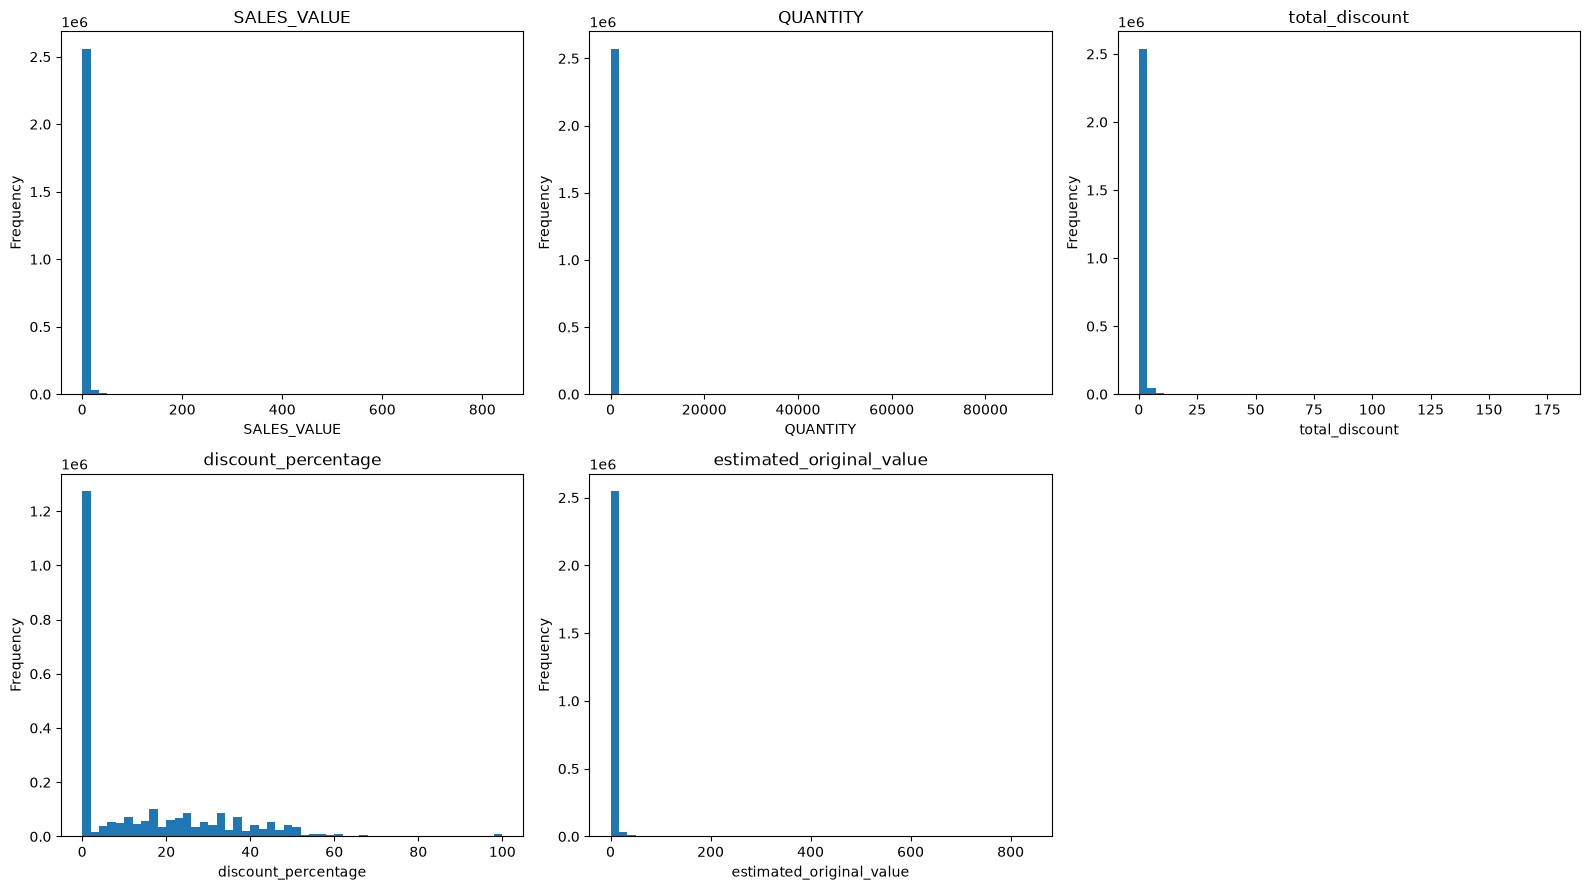

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(analysis_cols):
    axes[i].hist(transactions_promo[col].dropna(), bins=50)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

#### Zoomed Distribution Analysis

Visualise the central 99% of each variable to examine typical transaction patterns without removing extreme observations.

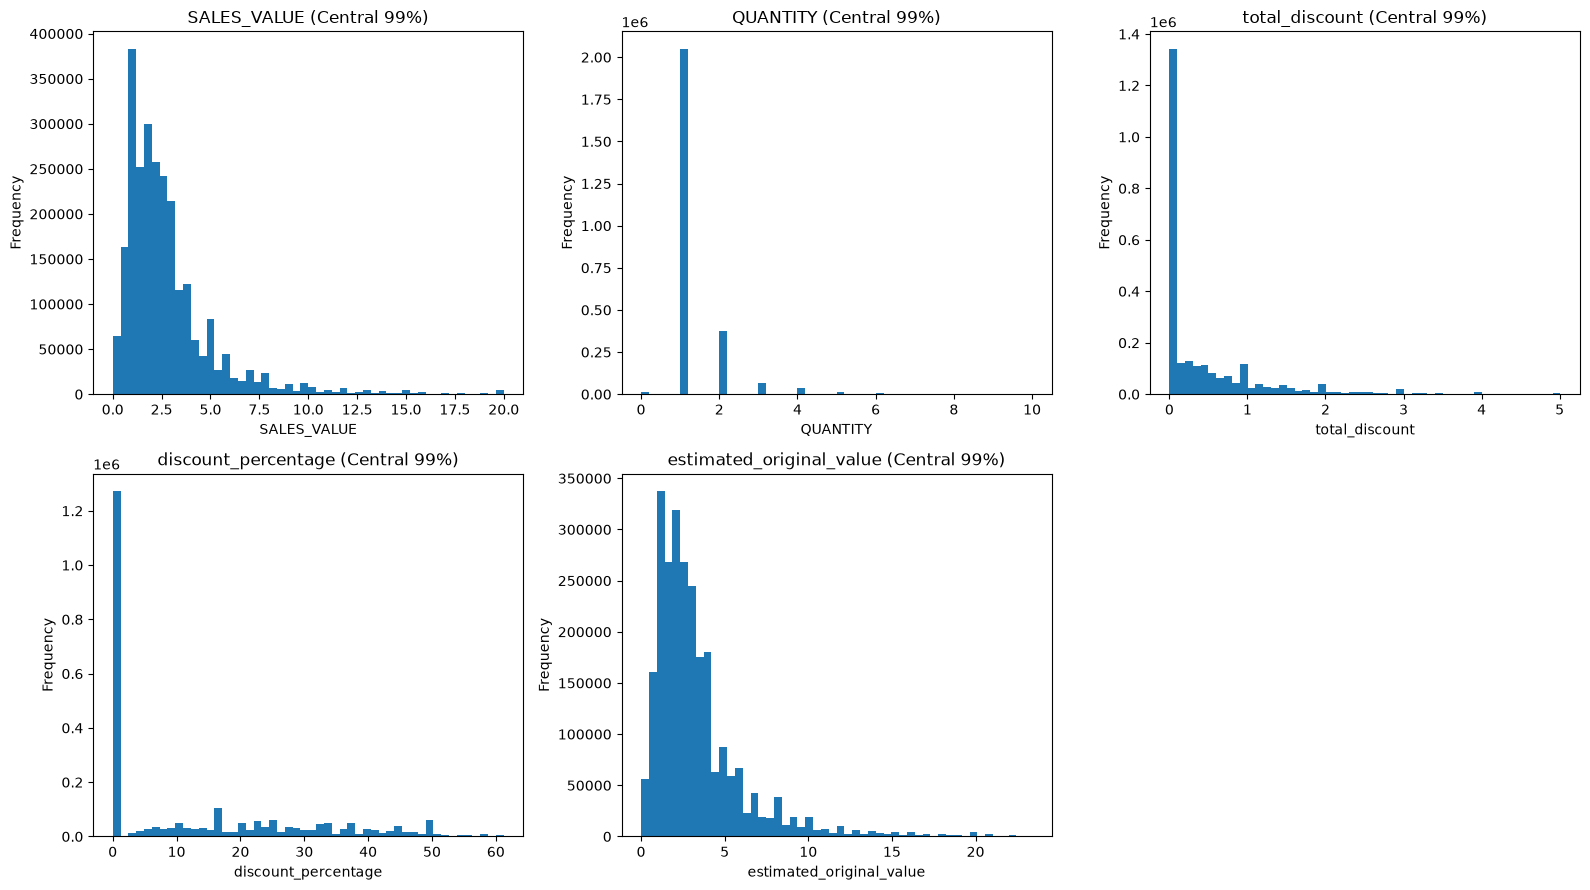

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(analysis_cols):
    data = transactions_promo[col].dropna()
    upper_limit = data.quantile(0.99)

    axes[i].hist(data[data <= upper_limit], bins=50)
    axes[i].set_title(f"{col} (Central 99%)")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

#### Box Plots of Numerical Variables

Use box plots to examine the spread, median and potential outliers in purchasing and discount-related variables.

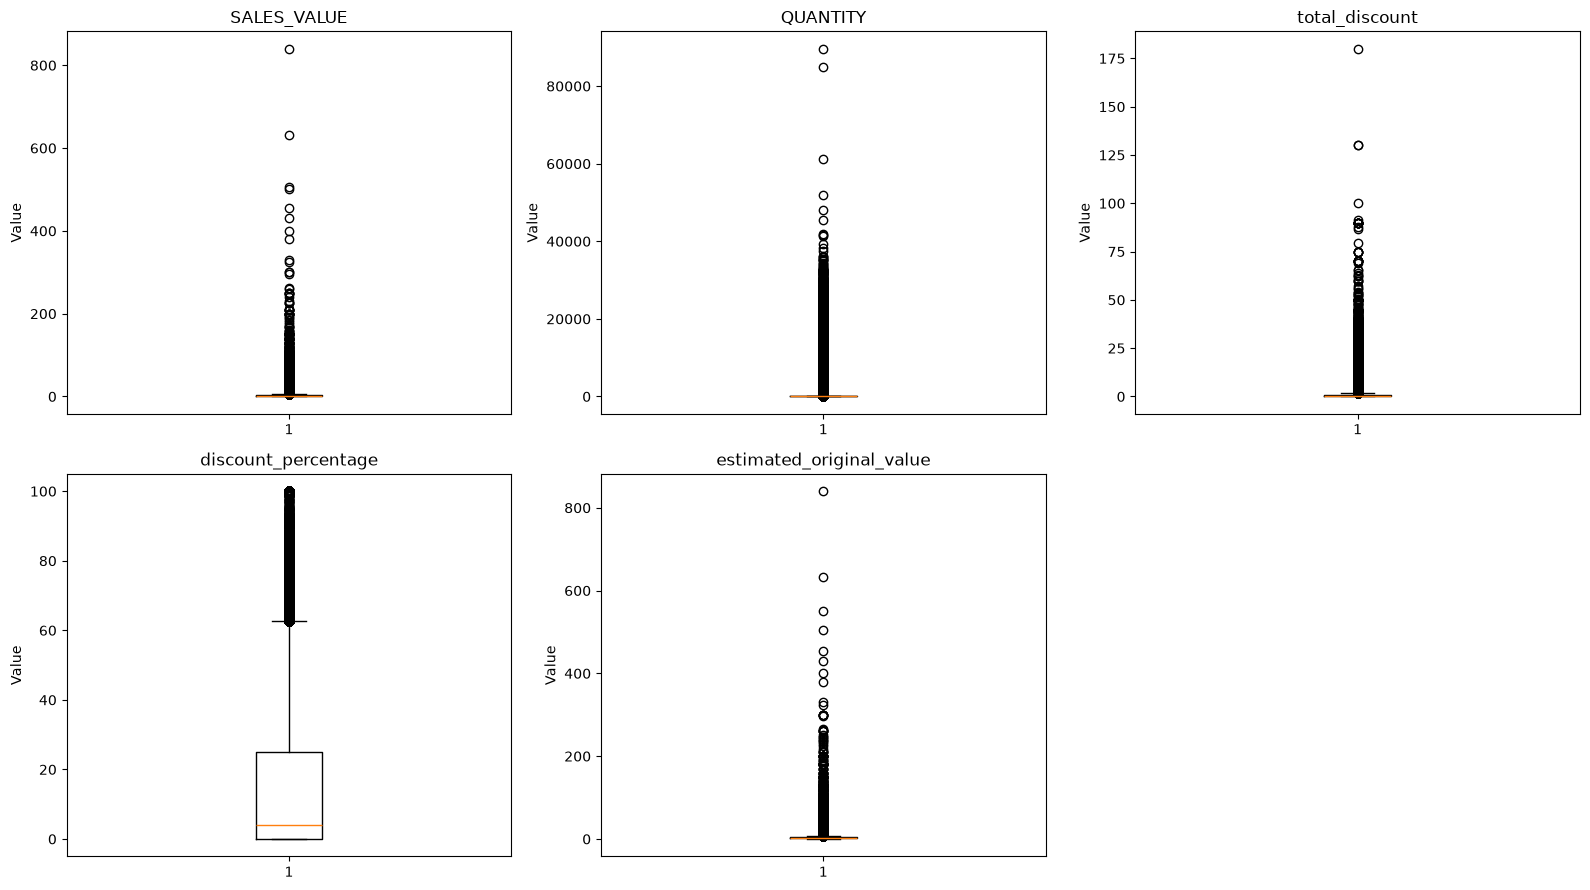

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(analysis_cols):
    axes[i].boxplot(transactions_promo[col].dropna())
    axes[i].set_title(col)
    axes[i].set_ylabel("Value")

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

#### Relationship Between Discount Percentage and Quantity

Use a scatter plot to examine whether transaction discount percentages are associated with the quantity purchased.

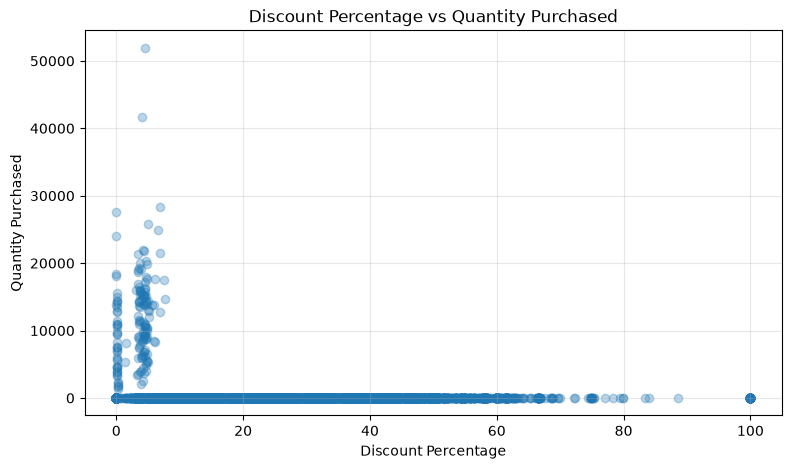

In [10]:
# Select records with valid discount percentages
scatter_data = transactions_promo[
    ["discount_percentage", "QUANTITY"]
].dropna()

# Use a reproducible sample to make the scatter plot readable
scatter_sample = scatter_data.sample(
    n=min(20000, len(scatter_data)),
    random_state=42
)

plt.figure(figsize=(9, 5))
plt.scatter(
    scatter_sample["discount_percentage"],
    scatter_sample["QUANTITY"],
    alpha=0.3
)

plt.title("Discount Percentage vs Quantity Purchased")
plt.xlabel("Discount Percentage")
plt.ylabel("Quantity Purchased")
plt.grid(alpha=0.3)
plt.show()

#### Correlation Between Discount Percentage and Quantity

Calculate Pearson correlation to measure the strength and direction of the linear relationship between discount percentage and quantity purchased.

In [11]:
correlation = transactions_promo[
    ["discount_percentage", "QUANTITY"]
].corr(method="pearson")

correlation

,discount_percentage,QUANTITY
discount_percentage,1.000000,-0.051541
QUANTITY,-0.051541,1.000000


#### Spearman Correlation Between Discount and Quantity

Calculate Spearman correlation to examine whether discount percentage and quantity have a monotonic relationship based on their ranks.

In [12]:
spearman_corr = transactions_promo[
    ["discount_percentage", "QUANTITY"]
].corr(method="spearman")

spearman_corr

,discount_percentage,QUANTITY
discount_percentage,1.000000,0.094275
QUANTITY,0.094275,1.000000


#### Covariance Between Discount and Quantity

Calculate covariance to examine whether discount percentage and quantity tend to vary in the same or opposite directions.

In [13]:
transactions_promo[
    ["discount_percentage", "QUANTITY"]
].cov()

,discount_percentage,QUANTITY
discount_percentage,311.255340,-1.050876e+03
QUANTITY,-1050.875959,1.330415e+06


#### Relationship Between Discount Percentage and Sales Value

Use a scatter plot to examine whether transactions with higher discount percentages are associated with higher sales values.

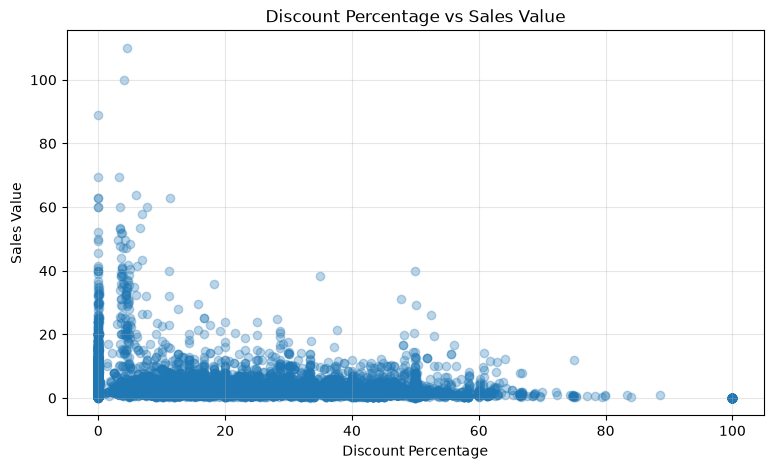

In [14]:
scatter_data = transactions_promo[
    ["discount_percentage", "SALES_VALUE"]
].dropna()

scatter_sample = scatter_data.sample(
    n=min(20000, len(scatter_data)),
    random_state=42
)

plt.figure(figsize=(9, 5))
plt.scatter(
    scatter_sample["discount_percentage"],
    scatter_sample["SALES_VALUE"],
    alpha=0.3
)

plt.title("Discount Percentage vs Sales Value")
plt.xlabel("Discount Percentage")
plt.ylabel("Sales Value")
plt.grid(alpha=0.3)
plt.show()

#### Correlation Between Discount Percentage and Sales Value

Calculate Pearson and Spearman correlations to examine linear and monotonic relationships between discount percentage and sales value.

In [15]:
sales_corr = transactions_promo[
    ["discount_percentage", "SALES_VALUE"]
].corr(method="pearson")

sales_spearman = transactions_promo[
    ["discount_percentage", "SALES_VALUE"]
].corr(method="spearman")

print("Pearson Correlation:")
display(sales_corr)

print("Spearman Correlation:")
display(sales_spearman)

Pearson Correlation:


,discount_percentage,SALES_VALUE
discount_percentage,1.000000,-0.109151
SALES_VALUE,-0.109151,1.000000


Spearman Correlation:


,discount_percentage,SALES_VALUE
discount_percentage,1.000000,-0.106367
SALES_VALUE,-0.106367,1.000000


#### Compare Discounted and Non-Discounted Transactions

Classify transactions into discounted and non-discounted groups using their total recorded discount.

In [16]:
transactions_promo["discount_status"] = (
    transactions_promo["total_discount"]
    .gt(0)
    .map({True: "Discounted", False: "Non-Discounted"})
)

print(transactions_promo["discount_status"].value_counts())

print("\nPercentage distribution:")
print(
    transactions_promo["discount_status"]
    .value_counts(normalize=True)
    .mul(100)
)

discount_status
Discounted        1319391
Non-Discounted    1276341
Name: count, dtype: int64

Percentage distribution:
discount_status
Discounted        50.829246
Non-Discounted    49.170754
Name: proportion, dtype: float64


#### Compare Purchasing Behaviour by Discount Status

Compare average and median sales values and quantities between discounted and non-discounted transactions.

In [17]:
discount_comparison = transactions_promo.groupby(
    "discount_status"
).agg(
    transaction_count=("BASKET_ID", "count"),
    mean_sales=("SALES_VALUE", "mean"),
    median_sales=("SALES_VALUE", "median"),
    mean_quantity=("QUANTITY", "mean"),
    median_quantity=("QUANTITY", "median"),
    mean_discount=("total_discount", "mean")
)

discount_comparison

,transaction_count,mean_sales,median_sales,mean_quantity,median_quantity,mean_discount
discount_status,,,,,,
Discounted,1319391,3.114272,2.00,196.282853,1.0,1.097878
Non-Discounted,1276341,3.093625,2.29,1.341171,1.0,0.000000


#### Quantity Distribution by Discount Status

Compare quantity quartiles across discounted and non-discounted records to understand differences in typical purchasing behaviour.

In [18]:
transactions_promo.groupby("discount_status")["QUANTITY"].describe()

,count,mean,std,min,25%,50%,75%,max
discount_status,,,,,,,,
Discounted,1319391.0,196.282853,1611.662504,0.0,1.0,1.0,1.0,89638.0
Non-Discounted,1276341.0,1.341171,36.367234,0.0,1.0,1.0,1.0,30080.0


#### Compare Larger Purchase Frequencies

Compare the proportion of transactions with quantities above selected thresholds across discounted and non-discounted groups.

In [19]:
quantity_comparison = transactions_promo.groupby("discount_status").agg(
    total_records=("QUANTITY", "count"),
    quantity_above_1=("QUANTITY", lambda x: (x > 1).sum()),
    quantity_above_5=("QUANTITY", lambda x: (x > 5).sum()),
    quantity_above_10=("QUANTITY", lambda x: (x > 10).sum())
)

for col in ["quantity_above_1", "quantity_above_5", "quantity_above_10"]:
    quantity_comparison[col + "_pct"] = (
        quantity_comparison[col] / quantity_comparison["total_records"] * 100
    )

quantity_comparison

,total_records,quantity_above_1,quantity_above_5,quantity_above_10,quantity_above_1_pct,quantity_above_5_pct,quantity_above_10_pct
discount_status,,,,,,,
Discounted,1319391,320325,33194,24324,24.278247,2.515858,1.843578
Non-Discounted,1276341,209974,8185,1082,16.451246,0.641286,0.084774


#### Load Product Information

Load the product dataset to examine whether product categories and brands influence the relationship between discounts and purchase quantities.

In [20]:
product = pd.read_csv("../data/raw/product.csv")

print("Product dataset shape:", product.shape)
print("\nColumns:")
print(product.columns.tolist())

product.head()

Product dataset shape: (92353, 7)

Columns:
['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']


,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,
3,26190,69,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,50 OZ
4,26355,69,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,14 OZ


#### Examine Product Categories

Identify the available product categories and brand information for grouping transactions.

In [21]:
category_cols = [
    col for col in product.columns
    if any(x in col.lower() for x in ["category", "department", "brand"])
]

product[category_cols].nunique()

DEPARTMENT    44
BRAND          2
dtype: int64

#### Inspect Product Commodity Groups

Check the number and quality of commodity categories before joining them with transaction records.

In [22]:
print("Unique commodities:", product["COMMODITY_DESC"].nunique())
print("Unique sub-commodities:", product["SUB_COMMODITY_DESC"].nunique())

print("\nMissing commodity descriptions:")
print(product["COMMODITY_DESC"].isna().sum())

print("\nPlaceholder commodity descriptions:")
print((product["COMMODITY_DESC"] == "NO COMMODITY DESCRIPTION").sum())

print("\nMost common commodities:")
product["COMMODITY_DESC"].value_counts().head(10)

Unique commodities: 308
Unique sub-commodities: 2383

Missing commodity descriptions:
0

Placeholder commodity descriptions:
490

Most common commodities:


COMMODITY_DESC
GREETING CARDS/WRAP/PARTY SPLY    2785
CANDY - PACKAGED                  2475
MAKEUP AND TREATMENT              2467
HAIR CARE PRODUCTS                1744
SOFT DRINKS                       1704
BAG SNACKS                        1523
HISPANIC                          1460
FRZN MEAT/MEAT DINNERS            1268
STATIONERY & SCHOOL SUPPLIES      1261
MAGAZINE                          1224
Name: count, dtype: int64

#### Validate Product IDs

Check whether each product ID maps to exactly one product record before merging.

In [23]:
print("Total product records:", len(product))
print("Unique product IDs:", product["PRODUCT_ID"].nunique())
print("Duplicate product IDs:", product["PRODUCT_ID"].duplicated().sum())

Total product records: 92353
Unique product IDs: 92353
Duplicate product IDs: 0


#### Load Enriched Transaction Data

Load transaction data containing product categories and brand information for further analysis.It was saved through nb2.

In [24]:
transactions_enriched = pd.read_csv(
    "../data/processed/transactions_enriched.csv",
    low_memory=False
)

print("Dataset shape:", transactions_enriched.shape)

Dataset shape: (2595732, 24)


#### Classify Discount Status

Classify each transaction record as discounted or non-discounted using its total discount.

In [25]:
transactions_enriched["discount_status"] = (
    transactions_enriched["total_discount"]
    .gt(0)
    .map({True: "Discounted", False: "Non-Discounted"})
)

transactions_enriched["discount_status"].value_counts()

discount_status
Discounted        1319391
Non-Discounted    1276341
Name: count, dtype: int64

#### Examine Purchase Records by Commodity

Count transaction records across commodity categories to understand their representation in the dataset.

In [26]:
commodity_counts = (
    transactions_enriched[
        transactions_enriched["COMMODITY_DESC"] != "NO COMMODITY DESCRIPTION"
    ]["COMMODITY_DESC"]
    .value_counts()
)

print("Number of commodity categories:", len(commodity_counts))
print("\nTop 15 commodities by transaction records:")
commodity_counts.head(15)

Number of commodity categories: 307

Top 15 commodities by transaction records:


COMMODITY_DESC
SOFT DRINKS                  117532
FLUID MILK PRODUCTS           85630
BAKED BREAD/BUNS/ROLLS        83232
CHEESE                        74885
BAG SNACKS                    67190
FRZN MEAT/MEAT DINNERS        56064
BEEF                          48726
SOUP                          46135
YOGURT                        44697
FROZEN PIZZA                  43362
VEGETABLES - SHELF STABLE     41612
COLD CEREAL                   37870
CANDY - CHECKLANE             35556
LUNCHMEAT                     35162
TROPICAL FRUIT                34442
Name: count, dtype: int64

#### Compare Purchase Quantities Across Commodities

Compare purchase quantities for discounted and non-discounted records within each commodity category.

In [27]:
commodity_data = transactions_enriched[
    transactions_enriched["COMMODITY_DESC"] != "NO COMMODITY DESCRIPTION"
].copy()

commodity_summary = (
    commodity_data
    .groupby(["COMMODITY_DESC", "discount_status"])
    .agg(
        total_records=("QUANTITY", "count"),
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median"),
        qty_above_1=("QUANTITY", lambda x: (x > 1).sum()),
        qty_above_5=("QUANTITY", lambda x: (x > 5).sum())
    )
    .reset_index()
)

commodity_summary["pct_qty_above_1"] = (
    commodity_summary["qty_above_1"] /
    commodity_summary["total_records"] * 100
)

commodity_summary["pct_qty_above_5"] = (
    commodity_summary["qty_above_5"] /
    commodity_summary["total_records"] * 100
)

commodity_summary.head()

,COMMODITY_DESC,discount_status,total_records,mean_quantity,median_quantity,qty_above_1,qty_above_5,pct_qty_above_1,pct_qty_above_5
0,,Discounted,4945,0.000000,0.0,0,0,0.000000,0.0
1,,Non-Discounted,2894,0.000000,0.0,0,0,0.000000,0.0
2,(CORP USE ONLY),Non-Discounted,61,1.245902,1.0,12,0,19.672131,0.0
3,ADULT INCONTINENCE,Discounted,303,1.207921,1.0,47,0,15.511551,0.0
4,ADULT INCONTINENCE,Non-Discounted,250,1.088000,1.0,21,0,8.400000,0.0


#### Filter Valid Commodity Descriptions

Exclude missing and placeholder commodity descriptions from the category-level analysis.

In [28]:
commodity_data = transactions_enriched[
    transactions_enriched["COMMODITY_DESC"].notna()
    & (
        transactions_enriched["COMMODITY_DESC"]
        != "NO COMMODITY DESCRIPTION"
    )
].copy()

print("Original records:", len(transactions_enriched))
print("Records with valid commodities:", len(commodity_data))
print(
    "Remaining missing descriptions:",
    commodity_data["COMMODITY_DESC"].isna().sum()
)

Original records: 2595732
Records with valid commodities: 2593381
Remaining missing descriptions: 0


#### Compare Purchase Quantities Across Commodities

Compare purchase quantities for discounted and non-discounted records within each valid commodity category.

In [29]:
commodity_summary = (
    commodity_data
    .groupby(["COMMODITY_DESC", "discount_status"])
    .agg(
        total_records=("QUANTITY", "count"),
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median"),
        qty_above_1=("QUANTITY", lambda x: (x > 1).sum()),
        qty_above_5=("QUANTITY", lambda x: (x > 5).sum())
    )
    .reset_index()
)

commodity_summary["pct_qty_above_1"] = (
    commodity_summary["qty_above_1"]
    / commodity_summary["total_records"] * 100
)

commodity_summary["pct_qty_above_5"] = (
    commodity_summary["qty_above_5"]
    / commodity_summary["total_records"] * 100
)

commodity_summary.head()

,COMMODITY_DESC,discount_status,total_records,mean_quantity,median_quantity,qty_above_1,qty_above_5,pct_qty_above_1,pct_qty_above_5
0,,Discounted,4945,0.000000,0.0,0,0,0.000000,0.0
1,,Non-Discounted,2894,0.000000,0.0,0,0,0.000000,0.0
2,(CORP USE ONLY),Non-Discounted,61,1.245902,1.0,12,0,19.672131,0.0
3,ADULT INCONTINENCE,Discounted,303,1.207921,1.0,47,0,15.511551,0.0
4,ADULT INCONTINENCE,Non-Discounted,250,1.088000,1.0,21,0,8.400000,0.0


#### Filter Valid Commodity Descriptions

Remove missing, blank, and placeholder commodity descriptions from the category-level analysis.

In [30]:
commodity_data = transactions_enriched.copy()

commodity_data["COMMODITY_DESC"] = (
    commodity_data["COMMODITY_DESC"]
    .astype("string")
    .str.strip()
)

commodity_data = commodity_data[
    commodity_data["COMMODITY_DESC"].notna()
    & commodity_data["COMMODITY_DESC"].ne("")
    & commodity_data["COMMODITY_DESC"].ne("NO COMMODITY DESCRIPTION")
].copy()

print("Original records:", len(transactions_enriched))
print("Records with valid commodities:", len(commodity_data))
print("Remaining missing descriptions:", commodity_data["COMMODITY_DESC"].isna().sum())
print("Remaining blank descriptions:", commodity_data["COMMODITY_DESC"].eq("").sum())

Original records: 2595732
Records with valid commodities: 2585542
Remaining missing descriptions: 0
Remaining blank descriptions: 0


In [31]:
commodity_summary = (
    commodity_data
    .groupby(["COMMODITY_DESC", "discount_status"])
    .agg(
        total_records=("QUANTITY", "count"),
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median"),
        qty_above_1=("QUANTITY", lambda x: (x > 1).sum()),
        qty_above_5=("QUANTITY", lambda x: (x > 5).sum())
    )
    .reset_index()
)

commodity_summary["pct_qty_above_1"] = (
    commodity_summary["qty_above_1"]
    / commodity_summary["total_records"] * 100
)

commodity_summary["pct_qty_above_5"] = (
    commodity_summary["qty_above_5"]
    / commodity_summary["total_records"] * 100
)

commodity_summary.head()

,COMMODITY_DESC,discount_status,total_records,mean_quantity,median_quantity,qty_above_1,qty_above_5,pct_qty_above_1,pct_qty_above_5
0,(CORP USE ONLY),Non-Discounted,61,1.245902,1.0,12,0,19.672131,0.000000
1,ADULT INCONTINENCE,Discounted,303,1.207921,1.0,47,0,15.511551,0.000000
2,ADULT INCONTINENCE,Non-Discounted,250,1.088000,1.0,21,0,8.400000,0.000000
3,AIR CARE,Discounted,3165,1.270774,1.0,642,8,20.284360,0.252765
4,AIR CARE,Non-Discounted,2391,1.187369,1.0,347,4,14.512756,0.167294


#### Identify Commodity-Level Quantity Differences

Compare the percentage of discounted and non-discounted records with quantities greater than one across commodities.

In [32]:
commodity_comparison = commodity_summary.pivot(
    index="COMMODITY_DESC",
    columns="discount_status",
    values="pct_qty_above_1"
)

commodity_comparison["difference"] = (
    commodity_comparison["Discounted"]
    - commodity_comparison["Non-Discounted"]
)

commodity_comparison = commodity_comparison.dropna()

commodity_comparison.sort_values(
    "difference",
    ascending=False
).head(15)

discount_status,Discounted,Non-Discounted,difference
COMMODITY_DESC,,,
TOYS,100.000000,0.000000,100.000000
FUEL,100.000000,0.056085,99.943915
COUPON/MISC ITEMS,99.974076,13.924320,86.049757
FLORAL-FLOWERING PLANTS,85.714286,13.207547,72.506739
SEWING,58.333333,5.917160,52.416174
HOME FREEZING & CANNING SUPPLY,75.000000,27.225131,47.774869
VITAMINS,50.472590,3.216374,47.256216
GARDEN CENTER,82.857143,38.086957,44.770186
LAXATIVES,54.201681,17.216412,36.985269


#### Check Commodity Sample Sizes

Examine the number of discounted and non-discounted records behind the largest quantity differences.

In [33]:
commodity_counts_comparison = commodity_summary.pivot(
    index="COMMODITY_DESC",
    columns="discount_status",
    values="total_records"
)

commodity_comparison = commodity_comparison.join(
    commodity_counts_comparison,
    rsuffix="_records"
)

commodity_comparison.sort_values(
    "difference",
    ascending=False
).head(15)

discount_status,Discounted,Non-Discounted,difference,Discounted_records,Non-Discounted_records
COMMODITY_DESC,,,,,
TOYS,100.000000,0.000000,100.000000,1.0,4.0
FUEL,100.000000,0.056085,99.943915,5.0,1783.0
COUPON/MISC ITEMS,99.974076,13.924320,86.049757,23145.0,4704.0
FLORAL-FLOWERING PLANTS,85.714286,13.207547,72.506739,28.0,477.0
SEWING,58.333333,5.917160,52.416174,12.0,169.0
HOME FREEZING & CANNING SUPPLY,75.000000,27.225131,47.774869,16.0,191.0
VITAMINS,50.472590,3.216374,47.256216,1058.0,1368.0
GARDEN CENTER,82.857143,38.086957,44.770186,70.0,575.0
LAXATIVES,54.201681,17.216412,36.985269,238.0,1243.0


#### Filter Categories by Sample Size

Retain commodity categories with at least 100 discounted and 100 non-discounted records for a more reliable comparison.

In [34]:
reliable_commodity_comparison = commodity_comparison[
    (commodity_comparison["Discounted_records"] >= 100)
    & (commodity_comparison["Non-Discounted_records"] >= 100)
].copy()

reliable_commodity_comparison.sort_values(
    "difference",
    ascending=False
).head(15)

discount_status,Discounted,Non-Discounted,difference,Discounted_records,Non-Discounted_records
COMMODITY_DESC,,,,,
COUPON/MISC ITEMS,99.974076,13.924320,86.049757,23145.0,4704.0
VITAMINS,50.472590,3.216374,47.256216,1058.0,1368.0
LAXATIVES,54.201681,17.216412,36.985269,238.0,1243.0
ANTACIDS,38.109306,3.135314,34.973992,677.0,1212.0
ANALGESICS,36.757069,2.667984,34.089084,1733.0,3036.0
HOT DOGS,51.206852,19.014755,32.192097,7706.0,4202.0
BERRIES,47.468744,15.829319,31.639425,4879.0,5812.0
BACON,41.813665,16.229461,25.584204,8050.0,3469.0
CORN,98.871528,76.463339,22.408188,1152.0,1623.0


#### Visualise Commodity-Level Quantity Differences

Plot the difference in multi-unit purchase percentages between discounted and non-discounted records across the leading commodity categories.

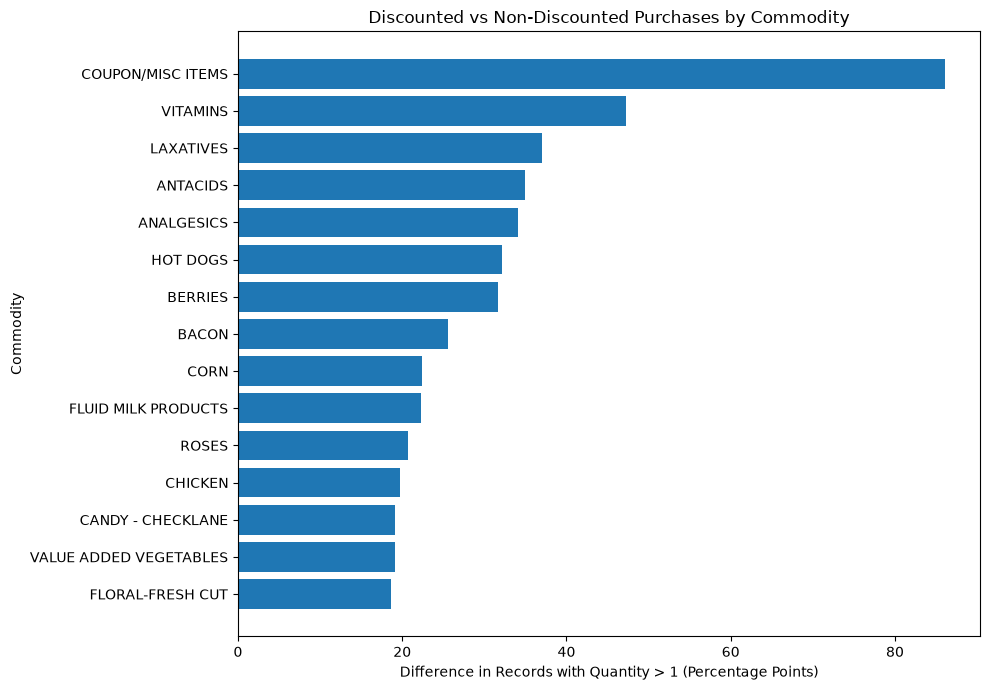

In [35]:
import matplotlib.pyplot as plt

plot_data = (
    reliable_commodity_comparison
    .sort_values("difference", ascending=False)
    .head(15)
    .sort_values("difference")
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data.index,
    plot_data["difference"]
)

plt.xlabel("Difference in Records with Quantity > 1 (Percentage Points)")
plt.ylabel("Commodity")
plt.title("Discounted vs Non-Discounted Purchases by Commodity")

plt.tight_layout()
plt.show()

#### Investigate Coupon/Misc Items

Examine the products within this category to understand its unusually high multi-unit purchase rate.

In [36]:
coupon_misc = commodity_data[
    commodity_data["COMMODITY_DESC"] == "COUPON/MISC ITEMS"
]

print("Records:", len(coupon_misc))

coupon_misc.groupby(
    ["discount_status", "SUB_COMMODITY_DESC"]
).agg(
    records=("QUANTITY", "count"),
    mean_quantity=("QUANTITY", "mean"),
    median_quantity=("QUANTITY", "median"),
    pct_qty_above_1=("QUANTITY", lambda x: (x > 1).mean() * 100)
).sort_values("records", ascending=False).head(20)

Records: 27849


records  mean_quantity  \
discount_status SUB_COMMODITY_DESC                                       
Discounted      GASOLINE-REG UNLEADED             23137   11113.415655   
Non-Discounted  MISC SALES TRANS                   1215       1.226337   
                MEAT SUPPLIES                       966       1.159420   
                PRODUCE DEPT KEY RING               696       1.170977   
                MISCELLANEOUS H & B AIDS            661       1.308623   
                ELECTRONIC GIFT CARDS ACTIVATI      436       1.066514   
                CAN DOG FOOD RATION (TRIX/VETS      190       1.431579   
                FLORAL DEPT KEY RING                131       1.374046   
                OUTSIDE VENDORS GIFT CARDS          112       1.312500   
                MISC. BATH PRODUCTS                  48       1.000000   
                BULK CANDY                           47       1.085106   
                GASOLINE-REG UNLEADED                37    2196.324324   
                MASTERCARD GIFT CARD                 35       1.085714   
                ELECTRONIC GIFT CARDS REFRESH        35       1.000000   
                SOFT DRINKS CAN NON-CARB (EXCE       33       1.303030   
                TICKETS                              22       2.227273   
                CENTRAL SUPPLIES                     19       1.052632   
                AMERICAN EXPRESS GIFT CARD           16       1.312500   
Discounted      JUICE                                 5       1.200000   
Non-Discounted  DONATIONS                             1       1.000000   

                                                median_quantity  \
discount_status SUB_COMMODITY_DESC                                
Discounted      GASOLINE-REG UNLEADED                   10775.0   
Non-Discounted  MISC SALES TRANS                            1.0   
                MEAT SUPPLIES                               1.0   
                PRODUCE DEPT KEY RING                       1.0   
                MISCELLANEOUS H & B AIDS                    1.0   
                ELECTRONIC GIFT CARDS ACTIVATI              1.0   
                CAN DOG FOOD RATION (TRIX/VETS              1.0   
                FLORAL DEPT KEY RING                        1.0   
                OUTSIDE VENDORS GIFT CARDS                  1.0   
                MISC. BATH PRODUCTS                         1.0   
                BULK CANDY                                  1.0   
                GASOLINE-REG UNLEADED                       1.0   
                MASTERCARD GIFT CARD                        1.0   
                ELECTRONIC GIFT CARDS REFRESH               1.0   
                SOFT DRINKS CAN NON-CARB (EXCE              1.0   
                TICKETS                                     2.0   
                CENTRAL SUPPLIES                            1.0   
                AMERICAN EXPRESS GIFT CARD                  1.0   
Discounted      JUICE                                       1.0   
Non-Discounted  DONATIONS                                   1.0   

                                                pct_qty_above_1  
discount_status SUB_COMMODITY_DESC                               
Discounted      GASOLINE-REG UNLEADED                100.000000  
Non-Discounted  MISC SALES TRANS                      16.543210  
                MEAT SUPPLIES                         12.836439  
                PRODUCE DEPT KEY RING                  9.913793  
                MISCELLANEOUS H & B AIDS              18.305598  
                ELECTRONIC GIFT CARDS ACTIVATI         2.981651  
                CAN DOG FOOD RATION (TRIX/VETS        15.789474  
                FLORAL DEPT KEY RING                  19.083969  
                OUTSIDE VENDORS GIFT CARDS            17.857143  
                MISC. BATH PRODUCTS                    4.166667  
                BULK CANDY                            14.893617  
                GASOLINE-REG UNLEADED                 27.027027  
                MAST

#### Examine Brand Distribution

Compare the number of discounted and non-discounted transaction records across National and Private brands.

In [37]:
brand_summary = (
    commodity_data
    .groupby(["BRAND", "discount_status"])
    .agg(
        total_records=("QUANTITY", "count"),
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median"),
        qty_above_1=("QUANTITY", lambda x: (x > 1).sum()),
        qty_above_5=("QUANTITY", lambda x: (x > 5).sum())
    )
    .reset_index()
)

brand_summary["pct_qty_above_1"] = (
    brand_summary["qty_above_1"]
    / brand_summary["total_records"] * 100
)

brand_summary["pct_qty_above_5"] = (
    brand_summary["qty_above_5"]
    / brand_summary["total_records"] * 100
)

brand_summary

,BRAND,discount_status,total_records,mean_quantity,median_quantity,qty_above_1,qty_above_5,pct_qty_above_1,pct_qty_above_5
0,National,Discounted,880267,1.354480,1.0,198143,6996,22.509420,0.794759
1,National,Non-Discounted,959115,1.257448,1.0,156924,6321,16.361333,0.659045
2,Private,Discounted,434035,593.918244,1.0,122145,26194,28.141740,6.034997
3,Private,Non-Discounted,312125,1.609791,1.0,52661,1798,16.871766,0.576051


#### Investigate Private Brand Quantity Outliers

Examine the quantity distribution of discounted Private brand records to identify extreme values affecting the mean.

In [38]:
private_discounted = commodity_data[
    (commodity_data["BRAND"] == "Private")
    & (commodity_data["discount_status"] == "Discounted")
]

print("Quantity distribution:")
print(private_discounted["QUANTITY"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
))

print("\nTop 10 commodities by mean quantity:")
print(
    private_discounted.groupby("COMMODITY_DESC")
    .agg(
        records=("QUANTITY", "count"),
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median"),
        max_quantity=("QUANTITY", "max")
    )
    .sort_values("mean_quantity", ascending=False)
    .head(10)
)

Quantity distribution:
count    434035.000000
mean        593.918244
std        2767.706148
min           1.000000
50%           1.000000
90%           3.000000
95%        3743.600000
99%       15327.000000
99.9%     23219.592000
max       89638.000000
Name: QUANTITY, dtype: float64

Top 10 commodities by mean quantity:
                                records  mean_quantity  median_quantity  \
COMMODITY_DESC                                                            
FUEL                                  5   17551.000000          17863.0   
COUPON/MISC ITEMS                 23140   11111.975022          10774.0   
HOME FREEZING & CANNING SUPPLY        2       3.000000              3.0   
SEAFOOD - SHELF STABLE             1789       2.704304              2.0   
BEANS - CANNED GLASS & MW          2113       2.209181              2.0   
VEGETABLES - SHELF STABLE         16853       2.051445              2.0   
MEAT - SHELF STABLE                2291       2.037538              2.0   
AUD

#### Compare Brand Quantities After Excluding Non-Standard Categories

Compare National and Private brand purchase quantities after excluding fuel and miscellaneous transaction categories that distort quantity averages.

In [39]:
brand_data = commodity_data[
    ~commodity_data["COMMODITY_DESC"].isin(
        ["FUEL", "COUPON/MISC ITEMS"]
    )
].copy()

brand_comparison = (
    brand_data
    .groupby(["BRAND", "discount_status"])
    .agg(
        total_records=("QUANTITY", "count"),
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median"),
        qty_above_1=("QUANTITY", lambda x: (x > 1).sum()),
        qty_above_5=("QUANTITY", lambda x: (x > 5).sum())
    )
    .reset_index()
)

brand_comparison["pct_qty_above_1"] = (
    brand_comparison["qty_above_1"]
    / brand_comparison["total_records"] * 100
)

brand_comparison["pct_qty_above_5"] = (
    brand_comparison["qty_above_5"]
    / brand_comparison["total_records"] * 100
)

brand_comparison

,BRAND,discount_status,total_records,mean_quantity,median_quantity,qty_above_1,qty_above_5,pct_qty_above_1,pct_qty_above_5
0,National,Discounted,880262,1.354481,1.0,198142,6996,22.509435,0.794763
1,National,Non-Discounted,958837,1.257446,1.0,156874,6319,16.360862,0.659028
2,Private,Discounted,410890,1.368853,1.0,99002,3052,24.094527,0.742778
3,Private,Non-Discounted,305916,1.255299,1.0,52055,1751,17.016109,0.572379


#### Visualise Brand-Level Quantity Differences

Compare the percentage of discounted and non-discounted records with quantities above one across National and Private brands.

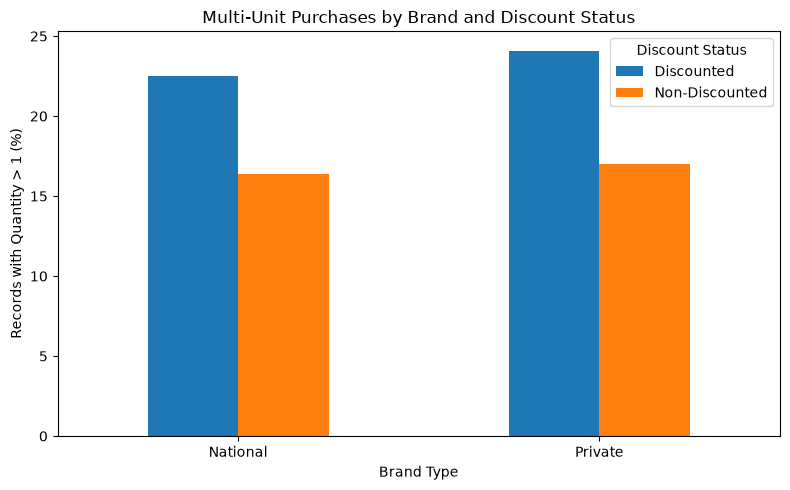

In [40]:
import matplotlib.pyplot as plt

brand_plot = brand_comparison.pivot(
    index="BRAND",
    columns="discount_status",
    values="pct_qty_above_1"
)

brand_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Records with Quantity > 1 (%)")
plt.xlabel("Brand Type")
plt.title("Multi-Unit Purchases by Brand and Discount Status")
plt.xticks(rotation=0)
plt.legend(title="Discount Status")
plt.tight_layout()
plt.show()

#### Examine Transaction Time Coverage

Inspect the day and week ranges to understand the time period covered by the transaction dataset.

In [41]:
print("Day range:", transactions_enriched["DAY"].min(),
      "to", transactions_enriched["DAY"].max())

print("Unique days:", transactions_enriched["DAY"].nunique())

print("\nWeek range:", transactions_enriched["WEEK_NO"].min(),
      "to", transactions_enriched["WEEK_NO"].max())

print("Unique weeks:", transactions_enriched["WEEK_NO"].nunique())

print("\nRecords per week:")
transactions_enriched["WEEK_NO"].value_counts().sort_index()

Day range: 1 to 711
Unique days: 711

Week range: 1 to 102
Unique weeks: 102

Records per week:


WEEK_NO
1       1881
2       3675
3       4803
4       5379
5       7168
       ...  
98     31153
99     32256
100    28902
101    26613
102    22423
Name: count, Length: 102, dtype: int64

#### Examine Weekly Transaction Distribution

Count transaction records in each week to identify variations in shopping activity over time.

In [42]:
weekly_records = (
    transactions_enriched
    .groupby("WEEK_NO")
    .size()
    .reset_index(name="total_records")
)

weekly_records.head(10)

,WEEK_NO,total_records
0,1,1881
1,2,3675
2,3,4803
3,4,5379
4,5,7168
5,6,8896
6,7,8980
7,8,10428
8,9,10585
9,10,13543


#### Visualise Weekly Transaction Activity

Plot the number of transaction records per week to identify changes in shopping activity over time.

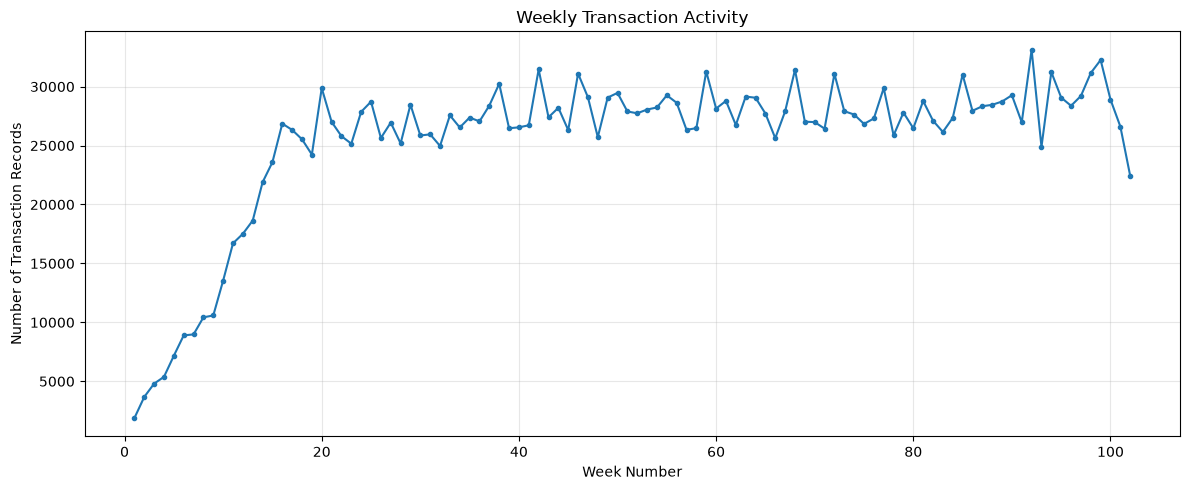

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_records["WEEK_NO"],
    weekly_records["total_records"],
    marker="o",
    markersize=3
)

plt.xlabel("Week Number")
plt.ylabel("Number of Transaction Records")
plt.title("Weekly Transaction Activity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Analyse Weekly Discount Patterns

Calculate the proportion of discounted transaction records in each week.

In [44]:
weekly_discount = (
    transactions_enriched
    .groupby("WEEK_NO")
    .agg(
        total_records=("discount_status", "count"),
        discounted_records=(
            "discount_status",
            lambda x: (x == "Discounted").sum()
        )
    )
    .reset_index()
)

weekly_discount["discount_percentage"] = (
    weekly_discount["discounted_records"]
    / weekly_discount["total_records"] * 100
)

weekly_discount.head(10)

,WEEK_NO,total_records,discounted_records,discount_percentage
0,1,1881,1041,55.342903
1,2,3675,2042,55.564626
2,3,4803,2670,55.590256
3,4,5379,2883,53.597323
4,5,7168,4113,57.380022
5,6,8896,4869,54.732464
6,7,8980,4721,52.572383
7,8,10428,5454,52.301496
8,9,10585,5769,54.501653
9,10,13543,6926,51.140811


#### Visualise Weekly Discount Patterns

Plot the percentage of discounted transaction records across all 102 weeks.

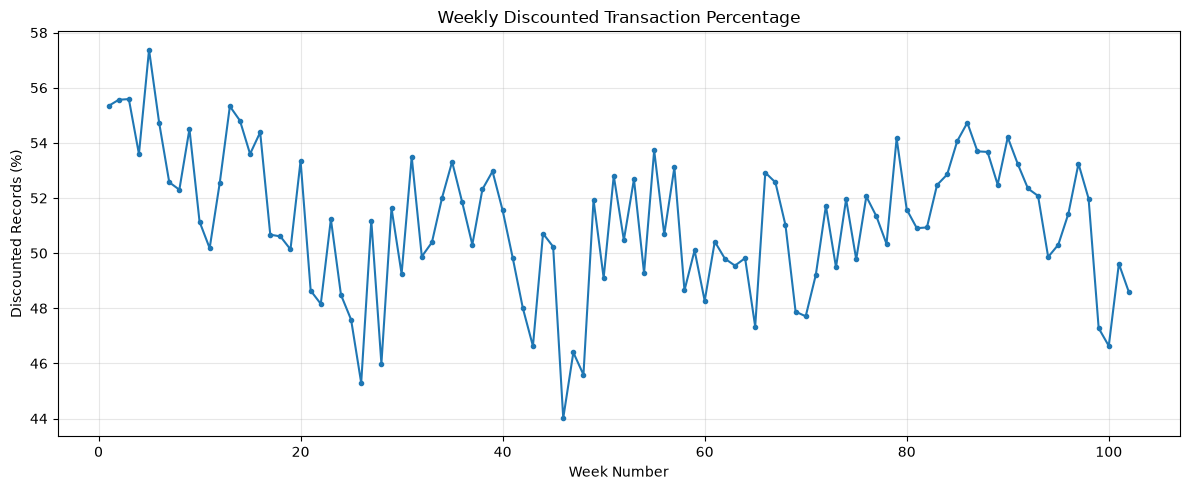

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_discount["WEEK_NO"],
    weekly_discount["discount_percentage"],
    marker="o",
    markersize=3
)

plt.xlabel("Week Number")
plt.ylabel("Discounted Records (%)")
plt.title("Weekly Discounted Transaction Percentage")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Analyse Weekly Purchase Quantities

Compare the average purchase quantity of discounted and non-discounted transaction records across weeks.

In [46]:
weekly_quantity = (
    transactions_enriched
    .groupby(["WEEK_NO", "discount_status"])
    .agg(
        mean_quantity=("QUANTITY", "mean"),
        median_quantity=("QUANTITY", "median")
    )
    .reset_index()
)

weekly_quantity.head(10)

,WEEK_NO,discount_status,mean_quantity,median_quantity
0,1,Discounted,1.305476,1.0
1,1,Non-Discounted,1.183333,1.0
2,2,Discounted,2.590108,1.0
3,2,Non-Discounted,1.184323,1.0
4,3,Discounted,17.307865,1.0
5,3,Non-Discounted,5.421472,1.0
6,4,Discounted,25.618800,1.0
7,4,Non-Discounted,1.204327,1.0
8,5,Discounted,21.088743,1.0
9,5,Non-Discounted,4.899509,1.0


#### Analyse Weekly Multi-Unit Purchases

Calculate the percentage of discounted and non-discounted transaction records with quantities greater than one across weeks.

In [47]:
weekly_multiunit = (
    transactions_enriched
    .groupby(["WEEK_NO", "discount_status"])
    .agg(
        total_records=("QUANTITY", "count"),
        multiunit_records=("QUANTITY", lambda x: (x > 1).sum())
    )
    .reset_index()
)

weekly_multiunit["multiunit_percentage"] = (
    weekly_multiunit["multiunit_records"]
    / weekly_multiunit["total_records"] * 100
)

weekly_multiunit.head(10)

,WEEK_NO,discount_status,total_records,multiunit_records,multiunit_percentage
0,1,Discounted,1041,231,22.190202
1,1,Non-Discounted,840,109,12.976190
2,2,Discounted,2042,512,25.073457
3,2,Non-Discounted,1633,215,13.165952
4,3,Discounted,2670,624,23.370787
5,3,Non-Discounted,2133,295,13.830286
6,4,Discounted,2883,650,22.545959
7,4,Non-Discounted,2496,359,14.383013
8,5,Discounted,4113,924,22.465354
9,5,Non-Discounted,3055,357,11.685761


#### Visualise Weekly Multi-Unit Purchase Patterns

Compare the percentage of discounted and non-discounted transaction records with quantities above one across all weeks.

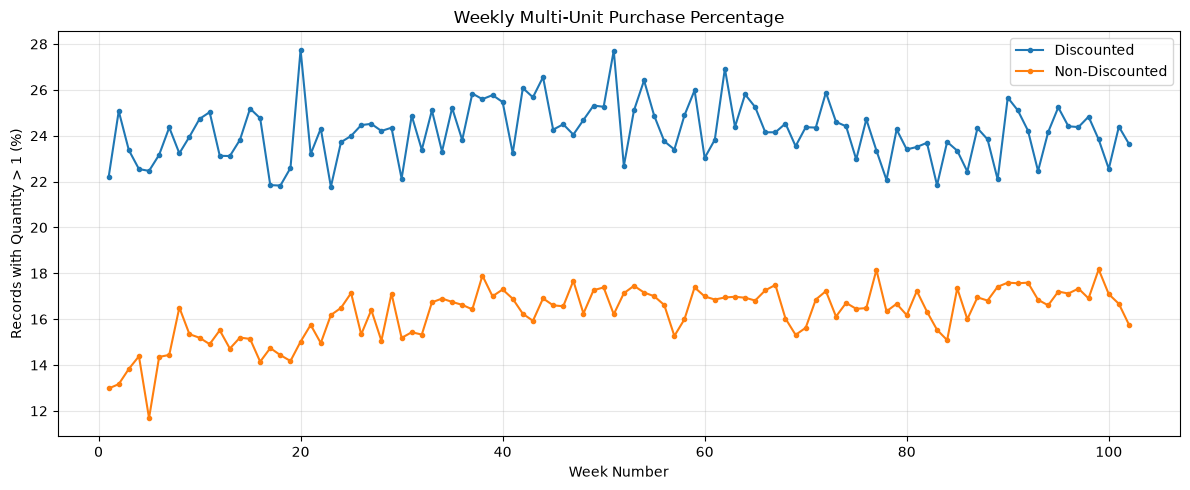

In [48]:
weekly_multiunit_plot = weekly_multiunit.pivot(
    index="WEEK_NO",
    columns="discount_status",
    values="multiunit_percentage"
)

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_multiunit_plot.index,
    weekly_multiunit_plot["Discounted"],
    label="Discounted",
    marker="o",
    markersize=3
)

plt.plot(
    weekly_multiunit_plot.index,
    weekly_multiunit_plot["Non-Discounted"],
    label="Non-Discounted",
    marker="o",
    markersize=3
)

plt.xlabel("Week Number")
plt.ylabel("Records with Quantity > 1 (%)")
plt.title("Weekly Multi-Unit Purchase Percentage")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Calculate Weekly Multi-Unit Purchase Differences

Calculate the average multi-unit purchase percentage for each discount group and the average difference across all weeks.

In [49]:
weekly_gap = (
    weekly_multiunit_plot["Discounted"]
    - weekly_multiunit_plot["Non-Discounted"]
)

print("Average discounted multi-unit percentage:",
      weekly_multiunit_plot["Discounted"].mean())

print("Average non-discounted multi-unit percentage:",
      weekly_multiunit_plot["Non-Discounted"].mean())

print("Average weekly difference (percentage points):",
      weekly_gap.mean())

print("Minimum weekly difference:",
      weekly_gap.min())

print("Maximum weekly difference:",
      weekly_gap.max())

Average discounted multi-unit percentage: 24.18889828421549
Average non-discounted multi-unit percentage: 16.22832734481421
Average weekly difference (percentage points): 7.9605709394012765
Minimum weekly difference: 4.681192370661051
Maximum weekly difference: 12.729837259485702


#### Calculate IQR for Numerical Variables

Calculate the first quartile, third quartile, and interquartile range to establish outlier boundaries.

In [50]:
outlier_cols = [
    "QUANTITY",
    "SALES_VALUE",
    "total_discount",
    "discount_percentage"
]

outlier_stats = transactions_enriched[outlier_cols].describe().T[
    ["25%", "50%", "75%"]
]

outlier_stats["IQR"] = (
    outlier_stats["75%"] - outlier_stats["25%"]
)

outlier_stats["lower_bound"] = (
    outlier_stats["25%"] - 1.5 * outlier_stats["IQR"]
)

outlier_stats["upper_bound"] = (
    outlier_stats["75%"] + 1.5 * outlier_stats["IQR"]
)

outlier_stats

,25%,50%,75%,IQR,lower_bound,upper_bound
QUANTITY,1.00,1.000000,1.000000,0.000000,1.000000,1.000000
SALES_VALUE,1.29,2.000000,3.490000,2.200000,-2.010000,6.790000
total_discount,0.00,0.070000,0.700000,0.700000,-1.050000,1.750000
discount_percentage,0.00,4.068038,25.062657,25.062657,-37.593985,62.656642


#### Identify Potential Outliers Using IQR

Count observations falling below the lower boundary or above the upper boundary for each numerical variable.

In [51]:
outlier_counts = []

for col in outlier_cols:
    lower = outlier_stats.loc[col, "lower_bound"]
    upper = outlier_stats.loc[col, "upper_bound"]

    lower_count = (transactions_enriched[col] < lower).sum()
    upper_count = (transactions_enriched[col] > upper).sum()

    outlier_counts.append({
        "variable": col,
        "lower_outliers": lower_count,
        "upper_outliers": upper_count,
        "total_outliers": lower_count + upper_count
    })

outlier_counts = pd.DataFrame(outlier_counts)

outlier_counts

,variable,lower_outliers,upper_outliers,total_outliers
0,QUANTITY,14466,530299,544765
1,SALES_VALUE,0,190644,190644
2,total_discount,0,215513,215513
3,discount_percentage,0,19871,19871


#### Visualise Potential Outliers Using Box Plots

Examine the distributions and potential extreme values in the numerical transaction variables.

/tmp/ipykernel_2614511/499387321.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_2614511/499387321.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_2614511/499387321.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_2614511/499387321.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


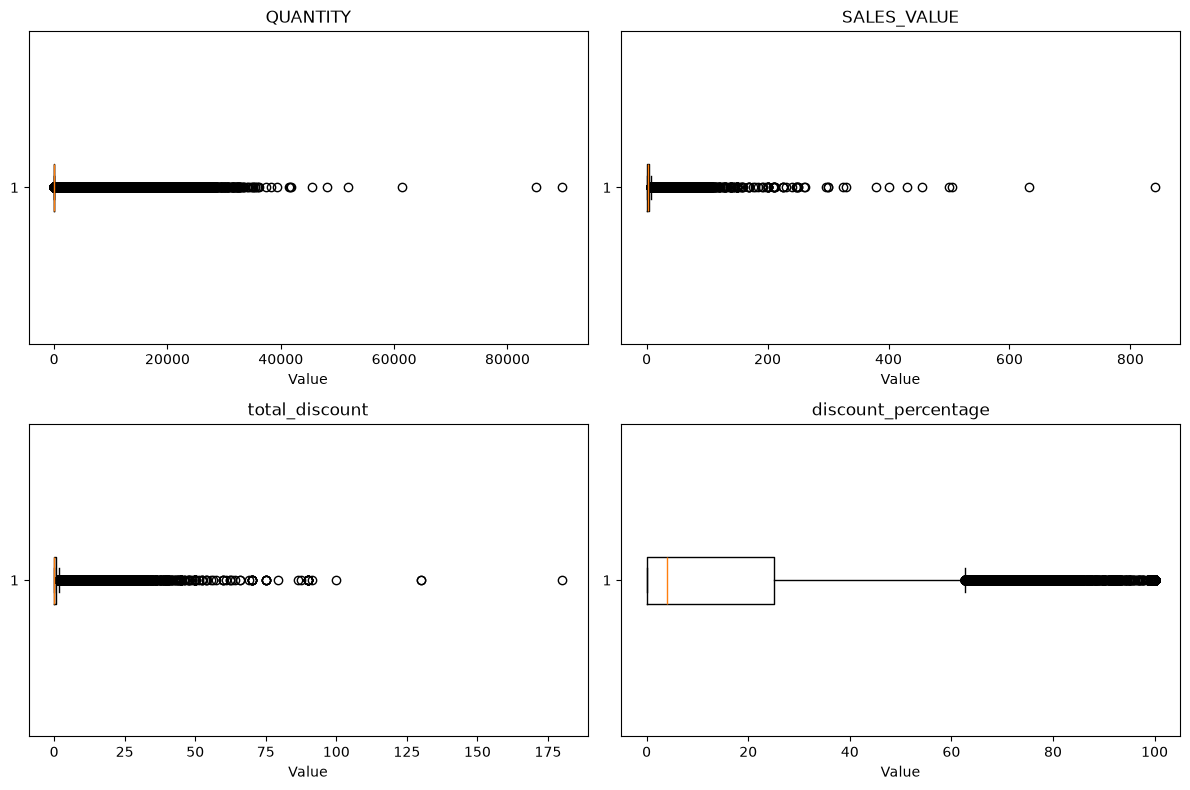

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), outlier_cols):
    ax.boxplot(
        transactions_enriched[col].dropna(),
        vert=False
    )
    ax.set_title(col)
    ax.set_xlabel("Value")

plt.tight_layout()
plt.show()

#### Investigate Extreme Purchase Quantities

Inspect transaction records with the highest quantities to identify unusually large purchases and their associated sales values and discounts.

In [53]:
transactions_enriched[
    [
        "PRODUCT_ID",
        "QUANTITY",
        "SALES_VALUE",
        "total_discount",
        "discount_percentage",
        "BRAND",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC"
    ]
].nlargest(20, "QUANTITY")

,PRODUCT_ID,QUANTITY,SALES_VALUE,total_discount,discount_percentage,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC
1750942,6534178,89638,250.00,13.45,5.105333,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
468356,6544236,85055,210.00,8.51,3.894559,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
481876,6534178,61335,150.21,6.13,3.920942,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
166536,6534178,51912,110.00,5.19,4.505599,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
1340882,6534178,48073,121.10,7.21,5.619203,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
2472791,6534178,45475,100.00,4.55,4.351985,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
1560340,6534178,41833,115.00,4.18,3.507300,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
376686,6534178,41686,100.00,4.17,4.003072,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
156049,6544236,41485,85.00,4.15,4.655076,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED
87625,6534178,39365,72.00,3.94,5.188307,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED


#### Investigate Extreme Quantities Outside Gasoline

Examine the largest purchase quantities after excluding gasoline records to identify other unusual product transactions.

In [54]:
non_gasoline = transactions_enriched[
    transactions_enriched["SUB_COMMODITY_DESC"]
    != "GASOLINE-REG UNLEADED"
]

non_gasoline[
    [
        "PRODUCT_ID",
        "QUANTITY",
        "SALES_VALUE",
        "total_discount",
        "discount_percentage",
        "BRAND",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC"
    ]
].nlargest(20, "QUANTITY")

,PRODUCT_ID,QUANTITY,SALES_VALUE,total_discount,discount_percentage,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC
1541674,911878,144,24.00,24.00,50.000000,National,CORN,CORN WHITE
1840749,1014675,90,9.00,0.00,0.000000,National,STATIONERY & SCHOOL SUPPLIES,BINDERS & PORTFOLIOS
528062,879948,74,43.01,1.02,2.316602,National,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING
621401,1080279,72,38.95,0.29,0.739042,National,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING
1018143,907994,72,18.00,24.84,57.983193,National,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING
2564403,6034249,72,8.64,9.36,52.000000,National,CANDY - PACKAGED,SEASONAL MISCELLANEOUS
1956516,879948,70,17.50,24.15,57.983193,National,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING
2342142,8358895,65,6.50,0.00,0.000000,National,CANDY - PACKAGED,CANDY BARS (SINGLES)(INCLUDING
15062,850841,60,82.60,12.80,13.417191,National,ISOTONIC DRINKS,ISOTONIC DRINKS SINGLE SERVE
428953,1053763,60,12.00,0.00,0.000000,National,PWDR/CRYSTL DRNK MX,SOFT DRINK POWDER POUCHES


#### Investigate Repeated High-Quantity Products

Examine products with the highest recorded quantities and check how frequently they appear in transaction records.

In [55]:
high_quantity_products = (
    non_gasoline
    .groupby(["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"])
    .agg(
        transaction_records=("QUANTITY", "count"),
        max_quantity=("QUANTITY", "max"),
        median_quantity=("QUANTITY", "median"),
        mean_quantity=("QUANTITY", "mean")
    )
    .sort_values("max_quantity", ascending=False)
)

high_quantity_products.head(15)

,,,transaction_records,max_quantity,median_quantity,mean_quantity
PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,,,,
911878,CORN,CORN WHITE,587,144,5.0,5.558773
1014675,STATIONERY & SCHOOL SUPPLIES,BINDERS & PORTFOLIOS,85,90,3.0,5.470588
879948,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING,516,74,1.0,2.430233
907994,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING,298,72,1.0,1.926174
6034249,CANDY - PACKAGED,SEASONAL MISCELLANEOUS,110,72,2.0,4.000000
1080279,CANDY - CHECKLANE,CANDY BARS (SINGLES)(INCLUDING,126,72,1.0,2.650794
8358895,CANDY - PACKAGED,CANDY BARS (SINGLES)(INCLUDING,36,65,2.0,6.111111
850841,ISOTONIC DRINKS,ISOTONIC DRINKS SINGLE SERVE,627,60,1.0,1.838915
1053763,PWDR/CRYSTL DRNK MX,SOFT DRINK POWDER POUCHES,934,60,2.0,2.925054


#### Examine Quantity Distributions of High-Quantity Products

Compare the quantity distributions of selected products to determine whether their maximum values are isolated extremes or part of broader purchasing patterns.

In [56]:
selected_products = [
    911878,
    1014675,
    879948,
    6034249,
    1080279
]

selected_quantity = non_gasoline[
    non_gasoline["PRODUCT_ID"].isin(selected_products)
]

selected_quantity.groupby("PRODUCT_ID")["QUANTITY"].describe(
    percentiles=[0.90, 0.95, 0.99]
)

,count,mean,std,min,50%,90%,95%,99%,max
PRODUCT_ID,,,,,,,,,
879948,516.0,2.430233,5.198672,0.0,1.0,4.0,5.0,12.00,74.0
911878,587.0,5.558773,6.899414,0.0,5.0,10.0,12.0,15.42,144.0
1014675,85.0,5.470588,10.343607,1.0,3.0,10.0,11.8,39.60,90.0
1080279,126.0,2.650794,6.565750,1.0,1.0,4.0,4.0,16.00,72.0
6034249,110.0,4.000000,7.838976,0.0,2.0,8.0,15.2,26.55,72.0


#### Investigate Extreme Sales Values

Inspect transaction records with the highest sales values to identify the products and circumstances associated with unusually large purchases.

In [57]:
transactions_enriched[
    [
        "PRODUCT_ID",
        "QUANTITY",
        "SALES_VALUE",
        "total_discount",
        "discount_percentage",
        "BRAND",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC"
    ]
].nlargest(20, "SALES_VALUE")

,PRODUCT_ID,QUANTITY,SALES_VALUE,total_discount,discount_percentage,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC
1085442,12484608,3,840.00,0.00,0.000000,Private,COUPON/MISC ITEMS,ELECTRONIC GIFT CARDS ACTIVATI
2030766,948670,5,631.80,0.00,0.000000,National,TICKETS,TICKETS
655985,1089093,2,505.00,0.00,0.000000,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION
1152895,13212959,1,499.99,50.00,9.091074,Private,SPRING/SUMMER SEASONAL,OUTDOOR ROLL-UP BLINDS
547657,1089093,1,455.00,0.00,0.000000,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION
526495,1089093,1,430.00,0.00,0.000000,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION
3600,1089093,1,400.00,0.00,0.000000,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION
2352647,1089093,1,380.00,0.00,0.000000,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION
1366400,13506935,1,329.99,0.00,0.000000,National,SPRING/SUMMER SEASONAL,PATIO SETS
807063,9296877,25,324.75,0.00,0.000000,National,GIFT & FRUIT BASKETS,FRUIT BASKETS


#### Investigate Extreme Discount Values

Inspect transactions with the highest total discounts to understand which products and purchases receive unusually large discounts.

In [58]:
transactions_enriched[
    [
        "PRODUCT_ID",
        "QUANTITY",
        "SALES_VALUE",
        "total_discount",
        "estimated_original_value",
        "discount_percentage",
        "BRAND",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC"
    ]
].nlargest(20, "total_discount")

,PRODUCT_ID,QUANTITY,SALES_VALUE,total_discount,estimated_original_value,discount_percentage,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC
2417859,17105530,2,79.98,180.00,259.98,69.236095,National,PREPAID WIRELESS&ACCESSORIES,MISC CARRIER
2208775,12810391,6,103.67,130.02,233.69,55.637811,National,PORK,ENHANCED
752808,12810391,7,105.75,129.98,235.73,55.139354,National,PORK,ENHANCED
2156344,17242362,1,199.99,100.00,299.99,33.334444,National,CHRISTMAS SEASONAL,ARTIFICIAL TREES
1259042,6978899,6,86.97,91.47,178.44,51.260928,National,VITAMINS,VITAMIN - NON HERBAL SUPPLEMEN
1419578,844179,40,152.21,90.05,242.26,37.170808,National,BEEF,PRIMAL
1242875,13095289,15,59.85,90.00,149.85,60.060060,Private,SEAFOOD - FROZEN,SEAFOOD-FRZ-IQF RAW SHRIMP RW
2214339,17105530,1,39.99,90.00,129.99,69.236095,National,PREPAID WIRELESS&ACCESSORIES,MISC CARRIER
2219193,17105530,1,39.99,90.00,129.99,69.236095,National,PREPAID WIRELESS&ACCESSORIES,MISC CARRIER
2273269,17105530,1,39.99,90.00,129.99,69.236095,National,PREPAID WIRELESS&ACCESSORIES,MISC CARRIER


#### Investigate Repeated High-Discount Products

Examine products with the highest discounts to determine whether large discount values occur repeatedly across transactions.

In [59]:
high_discount_products = (
    transactions_enriched[
        transactions_enriched["total_discount"] > 1.75
    ]
    .groupby(["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"])
    .agg(
        transaction_records=("total_discount", "count"),
        max_discount=("total_discount", "max"),
        median_discount=("total_discount", "median"),
        mean_discount=("total_discount", "mean"),
        max_discount_percentage=("discount_percentage", "max")
    )
    .sort_values("max_discount", ascending=False)
)

high_discount_products.head(15)

,,,transaction_records,max_discount,median_discount,mean_discount,max_discount_percentage
PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,,,,,
17105530,PREPAID WIRELESS&ACCESSORIES,MISC CARRIER,12,180.00,90.000,79.752500,69.236095
12810391,PORK,ENHANCED,378,130.02,19.200,20.728439,60.156632
17242362,CHRISTMAS SEASONAL,ARTIFICIAL TREES,1,100.00,100.000,100.000000,33.334444
6978899,VITAMINS,VITAMIN - NON HERBAL SUPPLEMEN,11,91.47,31.990,38.179091,52.459823
844179,BEEF,PRIMAL,1129,90.05,2.620,3.370585,78.205128
13095289,SEAFOOD - FROZEN,SEAFOOD-FRZ-IQF RAW SHRIMP RW,20,90.00,7.495,12.996500,60.060060
5569845,SOFT DRINKS,SOFT DRINKS 12/18&15PK CAN CAR,790,87.60,2.190,4.020013,65.229485
13511457,SOFT DRINKS,SOFT DRINKS 12/18&15PK CAN CAR,68,86.56,2.190,4.801176,65.229485
955914,HEAT/SERVE,OTHER - FULLY COOKED,6,79.36,3.000,15.726667,91.375936


#### Investigate High Discount Percentages

Examine transactions with discount percentages above the IQR upper boundary to understand their product distribution and frequency.

In [60]:
high_discount_percentage = transactions_enriched[
    transactions_enriched["discount_percentage"] > 62.656642
]

print("Records above IQR upper boundary:",
      len(high_discount_percentage))

print("\nTop commodities:")
print(
    high_discount_percentage["COMMODITY_DESC"]
    .value_counts()
    .head(15)
)

print("\nHighest discount percentages:")
high_discount_percentage[
    [
        "PRODUCT_ID",
        "SALES_VALUE",
        "total_discount",
        "discount_percentage",
        "COMMODITY_DESC",
        "SUB_COMMODITY_DESC"
    ]
].nlargest(15, "discount_percentage")

Records above IQR upper boundary: 19871

Top commodities:
COMMODITY_DESC
                          4945
LUNCHMEAT                  712
SOUP                       654
FRZN MEAT/MEAT DINNERS     645
CANDY - CHECKLANE          616
HOT DOGS                   615
ICE CREAM/MILK/SHERBTS     610
CHICKEN                    595
TOMATOES                   587
CANDY - PACKAGED           457
SOFT DRINKS                395
COOKIES                    395
DINNER SAUSAGE             370
COLD CEREAL                328
CHRISTMAS  SEASONAL        313
Name: count, dtype: int64

Highest discount percentages:


,PRODUCT_ID,SALES_VALUE,total_discount,discount_percentage,COMMODITY_DESC,SUB_COMMODITY_DESC
249,5978656,0.0,1.00,100.0,,
293,5978656,0.0,2.00,100.0,,
996,951412,0.0,1.48,100.0,VEGETABLES - ALL OTHERS,ASPARAGUS
1095,850115,0.0,3.29,100.0,SPICES & EXTRACTS,SPICES & SEASONINGS
1113,976872,0.0,2.49,100.0,SPICES & EXTRACTS,SPICES & SEASONINGS
1161,940108,0.0,1.19,100.0,VEGETABLES - SHELF STABLE,PEAS GREEN
1863,1114465,0.0,1.39,100.0,SPICES & EXTRACTS,SPICES & SEASONINGS
2143,5978656,0.0,2.19,100.0,,
2412,5978656,0.0,0.30,100.0,,
2611,961785,0.0,2.99,100.0,VALUE ADDED VEGETABLES,CUT VEGETABLES ALL OTHER


#### Investigate Zero-Sales Transactions

Examine transactions with zero sales value and positive discounts to understand their frequency and product distribution.

In [61]:
zero_sales_discount = transactions_enriched[
    (transactions_enriched["SALES_VALUE"] == 0)
    & (transactions_enriched["total_discount"] > 0)
]

print("Zero-sales records with discounts:", len(zero_sales_discount))

print("\nDiscount statistics:")
print(zero_sales_discount["total_discount"].describe())

print("\nTop products:")
print(
    zero_sales_discount.groupby(
        ["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
    )
    .size()
    .sort_values(ascending=False)
    .head(15)
)

Zero-sales records with discounts: 8707

Discount statistics:
count    8707.000000
mean        2.883530
std         2.399874
min         0.090000
25%         1.000000
50%         2.500000
75%         3.990000
max        39.950000
Name: total_discount, dtype: float64

Top products:
PRODUCT_ID  COMMODITY_DESC  SUB_COMMODITY_DESC
5978656                                           4887
1014948     COOKIES         COOKIES: REGULAR       111
1132911     COOKIES         COOKIES: REGULAR        74
910032      HOT DOGS        PREMIUM - MEAT          68
948384      COOKIES         COOKIES: REGULAR        62
1053282     COOKIES         COOKIES: REGULAR        52
1079228     BAG SNACKS      PRETZELS                45
827999      COOKIES         COOKIES: REGULAR        44
897752      BAG SNACKS      PRETZELS                39
911409      COOKIES         COOKIES: REGULAR        33
1131438     DINNER SAUSAGE  RED                     27
1127831     BERRIES         STRAWBERRIES            25
949965     

#### Investigate the Most Frequent Zero-Sales Product

Examine the transaction patterns and product information for the product appearing most frequently in zero-sales discounted records.

In [62]:
product_5978656 = zero_sales_discount[
    zero_sales_discount["PRODUCT_ID"] == 5978656
]

print("Number of records:", len(product_5978656))

print("\nProduct details:")
print(
    product_5978656[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "SUB_COMMODITY_DESC",
            "BRAND",
            "QUANTITY",
            "SALES_VALUE",
            "total_discount"
        ]
    ].describe(include="all")
)

print("\nDiscount distribution:")
print(product_5978656["total_discount"].value_counts().head(15))

print("\nQuantity distribution:")
print(product_5978656["QUANTITY"].value_counts().head(15))

Number of records: 4887

Product details:
        PRODUCT_ID COMMODITY_DESC SUB_COMMODITY_DESC     BRAND  QUANTITY  \
count       4887.0           4887               4887      4887    4887.0   
unique         NaN              1                  1         1       NaN   
top            NaN                                    National       NaN   
freq           NaN           4887               4887      4887       NaN   
mean     5978656.0            NaN                NaN       NaN       0.0   
std            0.0            NaN                NaN       NaN       0.0   
min      5978656.0            NaN                NaN       NaN       0.0   
25%      5978656.0            NaN                NaN       NaN       0.0   
50%      5978656.0            NaN                NaN       NaN       0.0   
75%      5978656.0            NaN                NaN       NaN       0.0   
max      5978656.0            NaN                NaN       NaN       0.0   

        SALES_VALUE  total_discount  
count  

#### Examine Remaining Zero-Sales Discounted Records

Check whether the remaining zero-sales transactions also contain zero quantities or represent different transaction patterns.

In [63]:
other_zero_sales = zero_sales_discount[
    zero_sales_discount["PRODUCT_ID"] != 5978656
]

print("Remaining records:", len(other_zero_sales))

print("\nQuantity distribution:")
print(other_zero_sales["QUANTITY"].describe())

print("\nQuantity frequencies:")
print(other_zero_sales["QUANTITY"].value_counts().head(15))

print("\nCommodity distribution:")
print(other_zero_sales["COMMODITY_DESC"].value_counts().head(15))

Remaining records: 3820

Quantity distribution:
count    3820.000000
mean        0.997906
std         0.190081
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         3.000000
Name: QUANTITY, dtype: float64

Quantity frequencies:
QUANTITY
1    3688
0      71
2      59
3       2
Name: count, dtype: int64

Commodity distribution:
COMMODITY_DESC
COOKIES                           388
LUNCHMEAT                         325
ICE CREAM/MILK/SHERBTS            251
DINNER SAUSAGE                    181
GREETING CARDS/WRAP/PARTY SPLY    180
BAG SNACKS                        174
HOT DOGS                          167
FROZEN PIE/DESSERTS               159
CHICKEN                            96
BERRIES                            89
SEAFOOD - FROZEN                   88
BREAKFAST SAUSAGE/SANDWICHES       79
BAKED SWEET GOODS                  78
HEAT/SERVE                         72
HAIR CARE PRODUCTS                 65
Name: count, dtype: int64


#### Examine Zero-Sales Transactions with Positive Quantities

Measure the frequency and discount distribution of transactions with positive quantities but zero sales value.

In [64]:
positive_quantity_zero_sales = zero_sales_discount[
    zero_sales_discount["QUANTITY"] > 0
]

print("Records:", len(positive_quantity_zero_sales))

print("\nTotal discount statistics:")
print(positive_quantity_zero_sales["total_discount"].describe())

print("\nDiscounted quantity distribution:")
print(positive_quantity_zero_sales["QUANTITY"].value_counts().sort_index())

print("\nDiscount percentage distribution:")
print(positive_quantity_zero_sales["discount_percentage"].describe())

Records: 3749

Total discount statistics:
count    3749.000000
mean        3.941462
std         2.063195
min         0.330000
25%         2.990000
50%         3.890000
75%         4.390000
max        39.950000
Name: total_discount, dtype: float64

Discounted quantity distribution:
QUANTITY
1    3688
2      59
3       2
Name: count, dtype: int64

Discount percentage distribution:
count    3749.0
mean      100.0
std         0.0
min       100.0
25%       100.0
50%       100.0
75%       100.0
max       100.0
Name: discount_percentage, dtype: float64


#### Investigate High Discount Percentages in Positive-Sales Transactions

Examine transactions above the IQR upper boundary after excluding zero-sales records.

In [65]:
high_discount_positive_sales = transactions_enriched[
    (transactions_enriched["discount_percentage"] > 62.656642)
    & (transactions_enriched["SALES_VALUE"] > 0)
]

print("Records:", len(high_discount_positive_sales))

print("\nDiscount percentage statistics:")
print(high_discount_positive_sales["discount_percentage"].describe())

print("\nTop commodities:")
print(
    high_discount_positive_sales["COMMODITY_DESC"]
    .value_counts()
    .head(15)
)

print("\nHighest discount percentage records:")
print(
    high_discount_positive_sales[
        [
            "PRODUCT_ID",
            "SALES_VALUE",
            "total_discount",
            "discount_percentage",
            "COMMODITY_DESC",
            "SUB_COMMODITY_DESC"
        ]
    ].nlargest(15, "discount_percentage")
)

Records: 11164

Discount percentage statistics:
count    11164.000000
mean        69.445993
std          6.100496
min         62.656827
25%         66.346154
50%         66.815644
75%         72.144847
max         99.799599
Name: discount_percentage, dtype: float64

Top commodities:
COMMODITY_DESC
SOUP                            654
FRZN MEAT/MEAT DINNERS          630
TOMATOES                        586
CANDY - CHECKLANE               551
CHICKEN                         499
HOT DOGS                        448
CANDY - PACKAGED                394
SOFT DRINKS                     389
LUNCHMEAT                       387
ICE CREAM/MILK/SHERBTS          359
COLD CEREAL                     326
CHRISTMAS  SEASONAL             312
VEGETABLES - SHELF STABLE       302
STATIONERY & SCHOOL SUPPLIES    224
BAKED BREAD/BUNS/ROLLS          206
Name: count, dtype: int64

Highest discount percentage records:
        PRODUCT_ID  SALES_VALUE  total_discount  discount_percentage  \
808602      624765       

#### Examine Products with Repeated High Discounts

Identify products that frequently appear in transactions with discount percentages above the IQR upper boundary.

In [66]:
high_discount_products = (
    high_discount_positive_sales.groupby(
        ["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
    )
    .agg(
        records=("discount_percentage", "size"),
        mean_discount=("discount_percentage", "mean"),
        median_discount=("discount_percentage", "median"),
        max_discount=("discount_percentage", "max")
    )
    .sort_values("records", ascending=False)
)

print("Unique products:", len(high_discount_products))

print("\nProducts with most high-discount records:")
print(high_discount_products.head(15))

Unique products: 3301

Products with most high-discount records:
                                                                   records  \
PRODUCT_ID COMMODITY_DESC          SUB_COMMODITY_DESC                        
854852     TOMATOES                TOMATOES HOTHOUSE ON THE VINE       571   
1135258    CHICKEN                 CHICKEN BREAST BONE IN              273   
1071342    COLD CEREAL             ALL FAMILY CEREAL                   169   
910032     HOT DOGS                PREMIUM - MEAT                      146   
15596515   COLD CEREAL             KIDS CEREAL                         126   
9416729    HOT DOGS                PREMIUM - MEAT                      122   
994928     EGGS                    EGGS - MEDIUM                       112   
957741     LUNCHMEAT               BOLOGNA                             109   
833715     SOUP                    RAMEN NOODLES/RAMEN CUPS            106   
854042     ICE CREAM/MILK/SHERBTS  TRADITIONAL                         102   

#### Compare High-Discount Frequency Across Products

Calculate the proportion of each product's transactions that have discount percentages above the IQR upper boundary.

In [67]:
product_discount_frequency = (
    transactions_enriched[
        transactions_enriched["SALES_VALUE"] > 0
    ]
    .groupby("PRODUCT_ID")
    .agg(
        total_records=("discount_percentage", "count"),
        high_discount_records=(
            "discount_percentage",
            lambda x: (x > 62.656642).sum()
        )
    )
)

product_discount_frequency["high_discount_percentage"] = (
    product_discount_frequency["high_discount_records"]
    / product_discount_frequency["total_records"] * 100
)

product_discount_frequency = (
    product_discount_frequency[
        product_discount_frequency["total_records"] >= 100
    ]
    .sort_values("high_discount_percentage", ascending=False)
)

print("Products examined:", len(product_discount_frequency))
print("\nTop products by high-discount percentage:")
print(product_discount_frequency.head(15))

Products examined: 5461

Top products by high-discount percentage:
            total_records  high_discount_records  high_discount_percentage
PRODUCT_ID                                                                
15596515              144                    126                 87.500000
1135258               493                    273                 55.375254
967751                108                     49                 45.370370
1085154               125                     54                 43.200000
9416729               295                    122                 41.355932
957741                267                    109                 40.823970
960942                135                     53                 39.259259
1051394               135                     50                 37.037037
854042                297                    102                 34.343434
9365106               174                     55                 31.609195
856788                121        

#### Identify Products with Frequent High Discounts

Retrieve product descriptions for the products with the highest proportions of high-discount transactions.

In [68]:
top_discount_products = (
    product_discount_frequency.head(15)
    .reset_index()
    .merge(
        transactions_enriched[
            ["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
        ].drop_duplicates("PRODUCT_ID"),
        on="PRODUCT_ID",
        how="left"
    )
)

print(
    top_discount_products[
        [
            "PRODUCT_ID",
            "COMMODITY_DESC",
            "SUB_COMMODITY_DESC",
            "total_records",
            "high_discount_records",
            "high_discount_percentage"
        ]
    ].to_string(index=False)
)

 PRODUCT_ID         COMMODITY_DESC             SUB_COMMODITY_DESC  total_records  high_discount_records  high_discount_percentage
   15596515            COLD CEREAL                    KIDS CEREAL            144                    126                 87.500000
    1135258                CHICKEN         CHICKEN BREAST BONE IN            493                    273                 55.375254
     967751            MEAT - MISC           SANDWICHES&HANDHELDS            108                     49                 45.370370
    1085154              LUNCHMEAT                        BOLOGNA            125                     54                 43.200000
    9416729               HOT DOGS                 PREMIUM - MEAT            295                    122                 41.355932
     957741              LUNCHMEAT                        BOLOGNA            267                    109                 40.823970
     960942          CANNED JUICES CRANBERRY JUICE (50% AND UNDER            135          

#### Review Missing Values

Identify missing values in the final enriched transaction dataset and examine which columns contain them.

In [69]:
missing_summary = pd.DataFrame({
    "missing_count": transactions_enriched.isnull().sum(),
    "missing_percentage": (
        transactions_enriched.isnull().sum()
        / len(transactions_enriched) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_count", ascending=False)

print("Total records:", len(transactions_enriched))
print("\nColumns containing missing values:")
print(missing_summary)

Total records: 2595732

Columns containing missing values:
                     missing_count  missing_percentage
display_values             2031958           78.280732
mailer_values              2031958           78.280732
promotion_records          2031958           78.280732
discount_percentage          10172            0.391874


#### Investigate Missing-Value Patterns

Verify whether missing promotion fields occur together and examine the conditions associated with missing discount percentages.

In [70]:
print("Promotion columns missing together:")
print(
    transactions_enriched[
        ["display_values", "mailer_values", "promotion_records"]
    ].isnull().all(axis=1).sum()
)

print("\nPromotion columns with partially missing values:")
print(
    transactions_enriched[
        ["display_values", "mailer_values", "promotion_records"]
    ].isnull().any(axis=1).sum()
    -
    transactions_enriched[
        ["display_values", "mailer_values", "promotion_records"]
    ].isnull().all(axis=1).sum()
)

print("\nMissing discount percentage conditions:")
print(
    transactions_enriched.loc[
        transactions_enriched["discount_percentage"].isnull(),
        "estimated_original_value"
    ].describe()
)

print(
    "\nNon-positive estimated original values:",
    (transactions_enriched["estimated_original_value"] <= 0).sum()
)

Promotion columns missing together:
2031958

Promotion columns with partially missing values:
0

Missing discount percentage conditions:
count    10172.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: estimated_original_value, dtype: float64

Non-positive estimated original values: 10172


#### Review Data Consistency and Noise

Check for negative values, infinite values and duplicate transaction records in the enriched dataset.

In [71]:
import numpy as np

numeric_cols = [
    "SALES_VALUE",
    "QUANTITY",
    "total_discount",
    "estimated_original_value",
    "discount_percentage"
]

print("Negative values:")
print((transactions_enriched[numeric_cols] < 0).sum())

print("\nInfinite values:")
print(
    np.isinf(transactions_enriched[numeric_cols])
    .sum()
)

print("\nDuplicate transaction rows:")
print(transactions_enriched.duplicated().sum())

Negative values:
SALES_VALUE                 0
QUANTITY                    0
total_discount              0
estimated_original_value    0
discount_percentage         0
dtype: int64

Infinite values:
SALES_VALUE                 0
QUANTITY                    0
total_discount              0
estimated_original_value    0
discount_percentage         0
dtype: int64

Duplicate transaction rows:
0


#### Log Transformation of Sales Value

Apply log1p transformation to reduce the right skewness of sales value while preserving zero values and the original data.

In [72]:
# Apply log1p transformation
transactions_enriched["SALES_VALUE_log"] = np.log1p(
    transactions_enriched["SALES_VALUE"]
)

# Compare skewness
print("Original skewness:",
      transactions_enriched["SALES_VALUE"].skew())

print("Transformed skewness:",
      transactions_enriched["SALES_VALUE_log"].skew())

Original skewness: 15.90747146266307
Transformed skewness: 1.0380320083891585


#### Compare Original and Transformed Sales Distributions

Visualise sales value before and after log transformation to compare their distribution shapes.

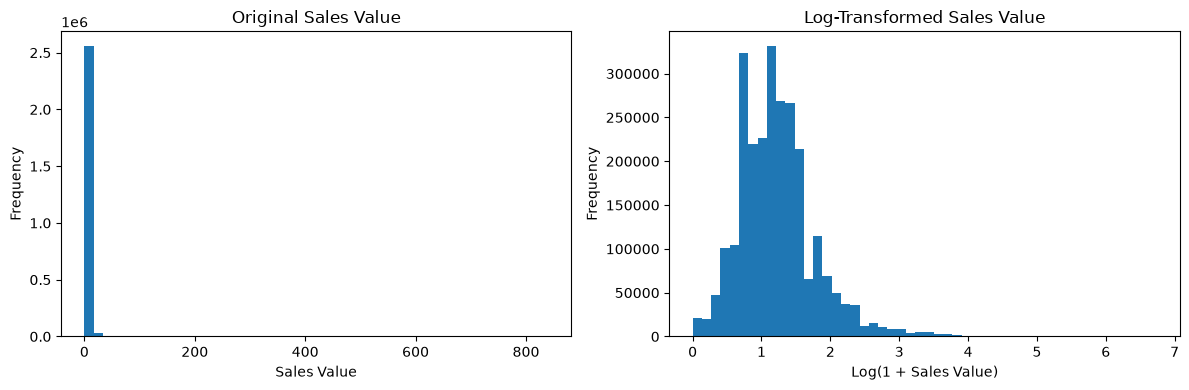

In [73]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(transactions_enriched["SALES_VALUE"], bins=50)
axes[0].set_title("Original Sales Value")
axes[0].set_xlabel("Sales Value")
axes[0].set_ylabel("Frequency")

axes[1].hist(transactions_enriched["SALES_VALUE_log"], bins=50)
axes[1].set_title("Log-Transformed Sales Value")
axes[1].set_xlabel("Log(1 + Sales Value)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Log Transformation of Quantity

Apply log1p transformation to reduce the right skewness of quantity while preserving zero values and the original data.

In [74]:
transactions_enriched["QUANTITY_log"] = np.log1p(
    transactions_enriched["QUANTITY"]
)

print("Original skewness:",
      transactions_enriched["QUANTITY"].skew())

print("Transformed skewness:",
      transactions_enriched["QUANTITY_log"].skew())

Original skewness: 13.642978796315347
Transformed skewness: 9.171603549445619


#### Square-Root Transformation of Quantity

Apply square-root transformation and compare its effect on the skewness of quantity.

In [75]:
transactions_enriched["QUANTITY_sqrt"] = np.sqrt(
    transactions_enriched["QUANTITY"]
)

print("Original skewness:",
      transactions_enriched["QUANTITY"].skew())

print("Log-transformed skewness:",
      transactions_enriched["QUANTITY_log"].skew())

print("Square-root transformed skewness:",
      transactions_enriched["QUANTITY_sqrt"].skew())

Original skewness: 13.642978796315347
Log-transformed skewness: 9.171603549445619
Square-root transformed skewness: 11.309192004600128


#### Log Transformation of Total Discount

Apply log1p transformation to reduce the right skewness of total discount while preserving zero values and the original data.


In [76]:
transactions_enriched["total_discount_log"] = np.log1p(
    transactions_enriched["total_discount"]
)

print("Original skewness:",
      transactions_enriched["total_discount"].skew())

print("Transformed skewness:",
      transactions_enriched["total_discount_log"].skew())

Original skewness: 13.004639789582061
Transformed skewness: 1.793336302569268


#### Compare Original and Log-Transformed Discounts

Visualise total discount before and after log transformation to compare their distribution shapes.

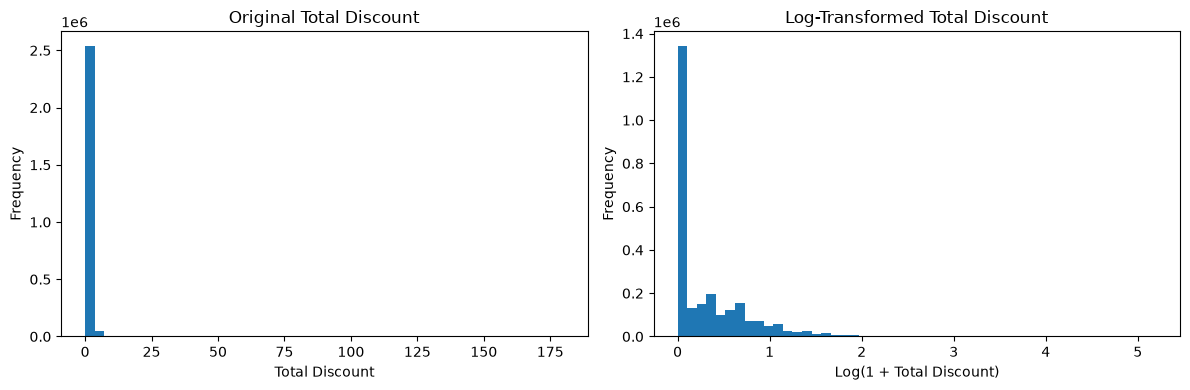

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(transactions_enriched["total_discount"], bins=50)
axes[0].set_title("Original Total Discount")
axes[0].set_xlabel("Total Discount")
axes[0].set_ylabel("Frequency")

axes[1].hist(transactions_enriched["total_discount_log"], bins=50)
axes[1].set_title("Log-Transformed Total Discount")
axes[1].set_xlabel("Log(1 + Total Discount)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Log Transformation of Estimated Original Value

Apply log1p transformation to reduce the right skewness of estimated original value while preserving zero values and the original data.

In [78]:
transactions_enriched["estimated_original_value_log"] = np.log1p(
    transactions_enriched["estimated_original_value"]
)

print("Original skewness:",
      transactions_enriched["estimated_original_value"].skew())

print("Transformed skewness:",
      transactions_enriched["estimated_original_value_log"].skew())

Original skewness: 13.522152283810952
Transformed skewness: 0.9216030310400547


#### Examine Discount Percentage Distribution

Visualise discount percentages to determine whether an additional transformation is necessary.

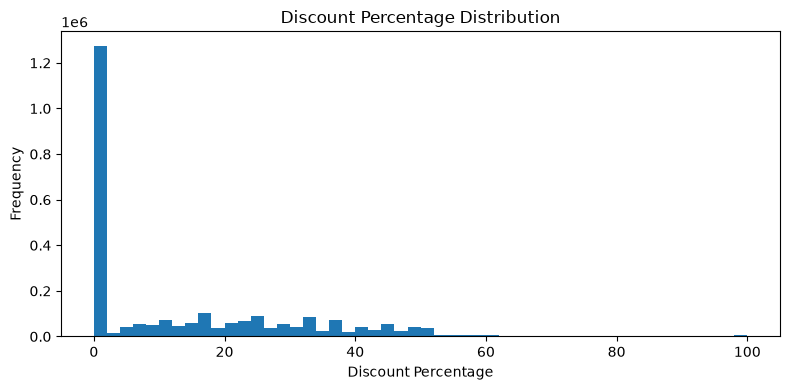

Skewness: 1.2427809055065688


In [79]:
plt.figure(figsize=(8, 4))

plt.hist(
    transactions_enriched["discount_percentage"].dropna(),
    bins=50
)

plt.title("Discount Percentage Distribution")
plt.xlabel("Discount Percentage")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

print(
    "Skewness:",
    transactions_enriched["discount_percentage"].skew()
)

#### Compare Skewness Before and After Transformation

Summarise the original and transformed skewness values to evaluate the effectiveness of the applied transformations.

In [80]:
skewness_comparison = pd.DataFrame({
    "Variable": [
        "SALES_VALUE",
        "QUANTITY",
        "total_discount",
        "estimated_original_value"
    ],
    "Original_Skewness": [
        transactions_enriched["SALES_VALUE"].skew(),
        transactions_enriched["QUANTITY"].skew(),
        transactions_enriched["total_discount"].skew(),
        transactions_enriched["estimated_original_value"].skew()
    ],
    "Transformed_Skewness": [
        transactions_enriched["SALES_VALUE_log"].skew(),
        transactions_enriched["QUANTITY_log"].skew(),
        transactions_enriched["total_discount_log"].skew(),
        transactions_enriched["estimated_original_value_log"].skew()
    ]
})

print(skewness_comparison.round(3))

                   Variable  Original_Skewness  Transformed_Skewness
0               SALES_VALUE             15.907                 1.038
1                  QUANTITY             13.643                 9.172
2            total_discount             13.005                 1.793
3  estimated_original_value             13.522                 0.922


#### Compare Different Power Transformations

Compare log, square-root, cube-root, Box-Cox and Yeo-Johnson transformations using skewness to identify suitable transformations for numerical variables.

In [81]:
from scipy.stats import boxcox, yeojohnson

# Variables to transform
variables = [
    "SALES_VALUE",
    "QUANTITY",
    "total_discount",
    "estimated_original_value"
]

transformation_results = []

for col in variables:

    x = transactions_enriched[col]

    # Original skewness
    original_skew = x.skew()

    # Log1p transformation
    log_skew = np.log1p(x).skew()

    # Square-root transformation
    sqrt_skew = np.sqrt(x).skew()

    # Cube-root transformation
    cbrt_skew = np.cbrt(x).skew()

    # Yeo-Johnson transformation
    yj_values, yj_lambda = yeojohnson(x)
    yj_skew = pd.Series(yj_values).skew()

    # Box-Cox transformation (positive values only)
    positive_values = x[x > 0]
    bc_values, bc_lambda = boxcox(positive_values)
    bc_skew = pd.Series(bc_values).skew()

    transformation_results.append({
        "Variable": col,
        "Original": original_skew,
        "Log1p": log_skew,
        "Square_Root": sqrt_skew,
        "Cube_Root": cbrt_skew,
        "Box_Cox": bc_skew,
        "Yeo_Johnson": yj_skew,
        "YJ_Lambda": yj_lambda,
        "BC_Lambda": bc_lambda
    })

transformation_comparison = pd.DataFrame(transformation_results)

print(transformation_comparison.round(3).to_string(index=False))

                Variable  Original  Log1p  Square_Root  Cube_Root  Box_Cox  Yeo_Johnson  YJ_Lambda  BC_Lambda
             SALES_VALUE    15.907  1.038        2.484      1.217    0.091       -0.017     -0.484      0.030
                QUANTITY    13.643  9.172       11.309     10.775    1.469       -0.286     -1.381     -3.154
          total_discount    13.005  1.793        1.541      0.639    0.020        0.499     -2.012      0.076
estimated_original_value    13.522  0.922        2.355      1.270   -0.012       -0.014     -0.433     -0.050


#### Visualise Yeo-Johnson Transformations

Compare the distributions of Yeo-Johnson-transformed variables to evaluate their shape and symmetry.

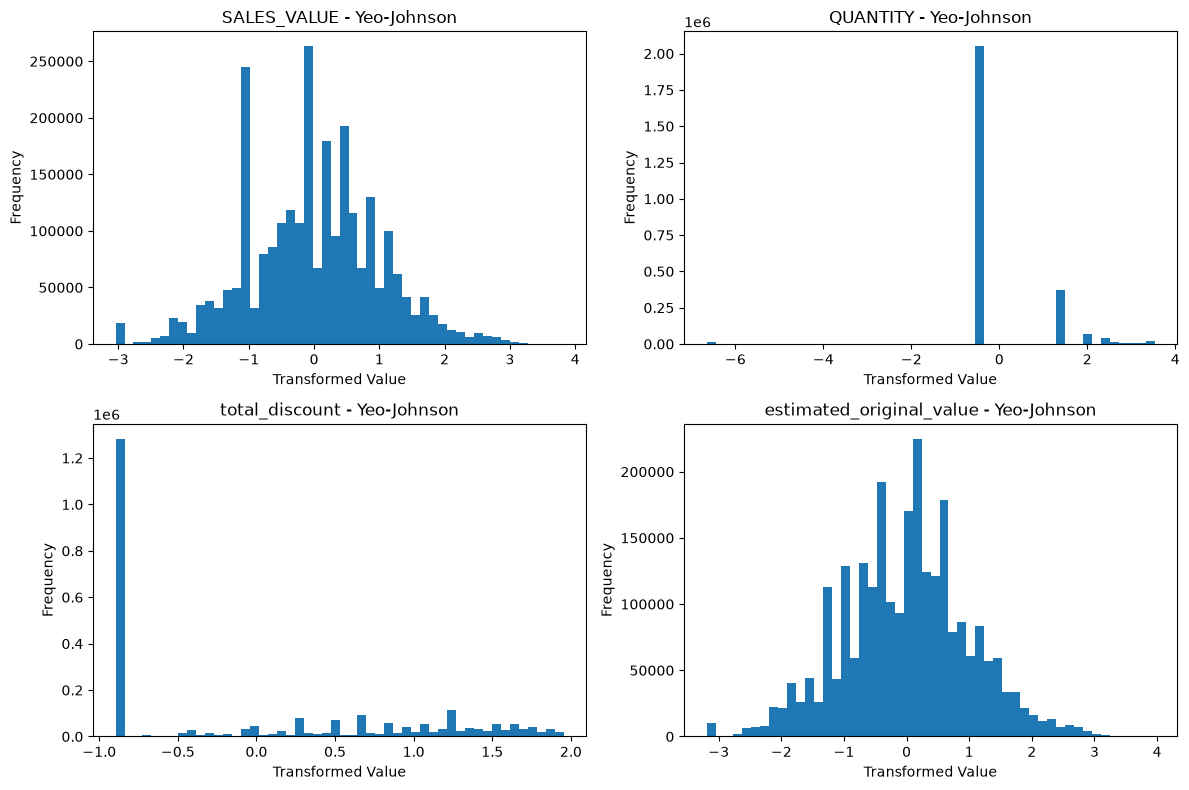

In [82]:
from sklearn.preprocessing import PowerTransformer

variables = [
    "SALES_VALUE",
    "QUANTITY",
    "total_discount",
    "estimated_original_value"
]

pt = PowerTransformer(method="yeo-johnson")

transformed_values = pt.fit_transform(
    transactions_enriched[variables]
)

for i, col in enumerate(variables):
    transactions_enriched[col + "_yeojohnson"] = transformed_values[:, i]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), variables):
    ax.hist(
        transactions_enriched[col + "_yeojohnson"],
        bins=50
    )
    ax.set_title(col + " - Yeo-Johnson")
    ax.set_xlabel("Transformed Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()